# **INTRODUZIONE ALLA PROGRAMMAZIONE MODULO 2 PROGETTO PYTHON 2025/26**
## **Demografia e narrazione mediatica degli stranieri in Italia (2013–2019)**
#### *- STUDENTI MELI FILIPPO, NAPONIELLO SIMONE, RUGGIERO MARCO*

---------------------------------------------------------------------------------------------------------------------------------------------------------

## **Introduzione**

*Questo progetto ha come obiettivo quello di analizzare il rapporto tra la presenza demografica degli stranieri in Italia e la loro rappresentazione nei media nel periodo 2013-2019, combinando dati quantitativi provenienti da due fonti: gli archivi ISTAT sulla popolazione residente per cittadinanza e il corpus di articoli del quotidiano "la Repubblica" (dataset Change-IT).*

*L'analisi si concentra su sei nazionalità, selezionate secondo un criterio misto: le 5 comunità straniere demograficamente più numerose in Italia (Romania, Albania, Marocco, Cina, Ucraina) e la Germania, inserita intenzionalmente come gruppo di controllo occidentale.*

*Dopo una fase preliminare dedicata all'importazione dei dataset e alla strutturazione e preparazione dei dati, l'analisi si articola in due sezioni principali:*

*1. **Quanto spazio mediatico?** — Attraverso un indice di sovrarappresentazione, si misura se ciascuna nazionalità riceve nei media un'attenzione proporzionale alla sua presenza demografica reale. Per ottenere una stima più prudente, viene sviluppata un'euristica che filtra i contesti non riferiti a persone. La correlazione di Pearson viene, infine, applicata per verificare se esiste un legame statistico tra incidenza demografica e visibilità mediatica nel tempo.*

*2. **Come vengono raccontati?** — Attraverso l'analisi delle tipologie di articoli in cui ciascuna nazionalità compare, si esamina il contesto narrativo in cui gli stranieri vengono rappresentati.*

*Il progetto consiste in un'analisi esplorativa volta a comprendere se i media funzionino effettivamente come uno 'specchio' della realtà demografica, oppure se seguano criteri editoriali propri, indipendenti dalla consistenza numerica delle comunità residenti.*


------------------------------------------------------------------------------------------------------------------------------------------------

## **PREPARAZIONE DEI DATI**

### **IMPORTAZIONE LIBRERIE**
- Pandas
- Numpy
- Matplotlib
- Seaborn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### **Pathlib per richiamare i percorsi file più velocemente nei passaggi successivi**

In [2]:
from pathlib import Path
import os
path = Path(os.getcwd())
path
path_repubblica = path / "dati_progetto" / "data" / "CHANGE-it" / "repubblica.csv"
path_istat = path / "dati_progetto" / "data" / "istat" / "Dati_RCS"

## **IMPORTAZIONE DATAFRAME**

### **1. Dataframe Repubblica**

In [3]:
df_repubblica_csv = pd.read_csv(path_repubblica)

df_repubblica_csv

,headline,full_text,url
0,"Commissione adozioni: ""Casi sospetti tra bimbi...",Nella lunga e complicata vicenda delle adozion...,NaN
1,"James Lovelock: ""Dieci anni fa ero certo che l...",L'ULTIMO REGALO DI JAMES LOVELOCK è un elisir ...,http://www.repubblica.it/ambiente/2016/10/02/n...
2,A Ezio Mauro il Premiolino 2017. Riconosciment...,MILANO - L'ex direttore di Repubblica Ezio Mau...,http://www.repubblica.it/cultura/2017/06/20/ne...
3,Ciampi ricoverato a Bolzano,BOLZANO - Il presidente emerito Carlo Azeglio ...,http://www.repubblica.it/politica/2014/07/11/n...
4,"Pordenone, ritrovati i tre ragazzi dispersi su...",ANDREIS (PORDENONE) - Paura e poi sollievo per...,http://www.repubblica.it/cronaca/2014/08/16/ne...
...,...,...,...
63696,"Statue coperte, l'ira di Renzi: ""Qualcuno pagh...","ROMA - ""Voglio una relazione scritta entro que...",http://www.repubblica.it/politica/2016/01/28/n...
63697,"Addio al sogno di Miranda, Cuomo vince le prim...","No, Miranda Hobbs non sarà governatrice dello ...",http://www.repubblica.it/esteri/2018/09/14/new...
63698,"Test Medicina, caos sul numero chiuso, Palazzo...",E' mattina presto quando nel comunicato stampa...,http://www.repubblica.it/cronaca/2018/10/16/ne...
63699,"'Tecno-solitudine', il migliore è 'La telecame...","AVEVAMO dato un tema, la Tecno-solitudine . Lo...",https://www.repubblica.it/tecnologia/2014/02/2...


### **2. Dataframe cittadinanza, importazione di tutti i csv**

In [4]:
lista_dataframe_cittadinanza = []

for anno in range(2002, 2026):
    df = pd.read_csv(path_istat / f"Dati_cittadinanza_{anno}.csv", 
                     sep=";", 
                     dtype={"Codice Istat": "string"})

    lista_dataframe_cittadinanza.append(df)


df_cittadinanza_csv = pd.concat(lista_dataframe_cittadinanza, ignore_index=True)
df_cittadinanza_csv.head(5)

,Anno,Codice Istat,Denominazione,Codice stato di cittadinanza,Stato di cittadinanza,Zona,Continente,Maschi,Femmine,Totale
0,2002,001001,Agliè,100,Italia,Unione Europea,Europa,1205,1325,2530
1,2002,001001,Agliè,201,Albania,Europa Centro-Orientale,Europa,2,0,2
2,2002,001001,Agliè,314,Cina,Asia Orientale,Asia,1,0,1
3,2002,001001,Agliè,215,Francia,Unione Europea,Europa,0,1,1
4,2002,001001,Agliè,436,Marocco,Africa Settentrionale,Africa,4,0,4


## **OPERAZIONI SUI DATAFRAME**

## **Dataframe repubblica**


### **Elaborazione del testo: tokenizzazione degli articoli**

*In questa fase, sia i titoli (`headline`) che i testi completi (`full_text`) degli articoli vengono sottoposti a un processo di pulizia testuale. Il procedimento prevede:*

* *La gestione dei valori mancanti (sostituiti con stringhe vuote).*
* *La conversione di tutto il testo in minuscolo.*
* *La sostituzione di apostrofi e trattini con spazi vuoti, per separare correttamente le parole composte o elise.*
* *La rimozione di tutta la punteggiatura e dei caratteri speciali.*
* *L'eliminazione degli spazi bianchi multipli o in eccesso.*

*Questo passaggio garantisce che il testo sia uniforme e pronto per le analisi successive.*

In [5]:
tokenizzazione_text = (df_repubblica_csv["full_text"]
                                            .fillna("")
                                            .str.lower()
                                            .str.replace(r"['`-]", " ", regex=True)
                                            .str.replace(r"[^\w\s]", " ", regex=True)
                                            .str.replace(r"\s+", " ", regex=True)
                                            .str.strip())

tokenizzazione_headline = (df_repubblica_csv["headline"]
                                            .fillna("")
                                            .str.lower()
                                            .str.replace(r"['`-]", " ", regex=True)
                                            .str.replace(r"[^\w\s]", " ", regex=True)
                                            .str.replace(r"\s+", " ", regex=True)
                                            .str.strip())


### **Visualizzazione tokenizzazione**

In [6]:
from pprint import pprint
liste_di_token = tokenizzazione_text.str.split()
df_liste_di_token = liste_di_token.to_frame()
prima_riga_string = " ".join(df_liste_di_token.loc[0].explode())
pprint(prima_riga_string)

('nella lunga e complicata vicenda delle adozioni in congo c è un ombra '
 'pesante alcuni dei bambini arrivati in italia negli ultimi anni non '
 'sarebbero stati adottabili perché avevano una famiglia naturale alla quale '
 'sarebbero stati sottratti con l inganno e presumibilmente dietro pagamento '
 'di somme di denaro a denunciare questa vicenda è stata oggi la '
 'vicepresidente della commissione adozioni internazionali cai silvia della '
 'monica nel corso di un convegno promosso dal senatore maurizio romani idv '
 'gruppo misto della monica ha spiegato che sulla vicenda la commissione ha '
 'avviato accertamenti e che è stata interessata l autorità giudiziaria se i '
 'bambini sono stati strappati alle famiglie e gli enti ne erano consapevoli '
 'ci sono precise responsabilità da accertare ha detto ha poi ricordato che di '
 'questi fatti si era occupato il settimanale l espresso nel luglio scorso in '
 'un inchiesta che citava l ente accreditato per le adozioni amici dei bambi

In [7]:
tokenizzazione_text.tail(10)
tokenizzazione_headline.shape #(63701,)
tokenizzazione_text.shape #(63701,)
tokenizzazione_headline.name = "headline_tokenizzata" 
tokenizzazione_text.name = "text_tokenizzato" 
tokenizzazione_text 

0        nella lunga e complicata vicenda delle adozion...
1        l ultimo regalo di james lovelock è un elisir ...
2        milano l ex direttore di repubblica ezio mauro...
3        bolzano il presidente emerito carlo azeglio ci...
4        andreis pordenone paura e poi sollievo per tre...
                               ...                        
63696    roma voglio una relazione scritta entro questa...
63697    no miranda hobbs non sarà governatrice dello s...
63698    e mattina presto quando nel comunicato stampa ...
63699    avevamo dato un tema la tecno solitudine lo sc...
63700    roma i lefebvriani rompono ogni rapporto con l...
Name: text_tokenizzato, Length: 63701, dtype: str

## **Esplorazione del dataset**


### **Estrazione di anno e tipologia dall'url di ogni articolo**

In [8]:
estrazione_anno = df_repubblica_csv["url"].str.extract(r"/(\d{4})/")
estrazione_tipologia = df_repubblica_csv["url"].str.extract(r"repubblica\.it/([^/]+)/")
estrazione_anno.columns = ["anno"]
estrazione_tipologia.columns = ["tipologia"]
df_anno_tipologia = estrazione_anno.join(estrazione_tipologia)
df_anno_tipologia

,anno,tipologia
0,NaN,NaN
1,2016,ambiente
2,2017,cultura
3,2014,politica
4,2014,cronaca
...,...,...
63696,2016,politica
63697,2018,esteri
63698,2018,cronaca
63699,2014,tecnologia


#### **Alcune verifiche**
*Controllo delle tipologie uniche all'interno del df, ordinamento dei valori, controllo della dimensione e della quantità di valori nulli.*

In [9]:
valori_unici_tipologia = df_anno_tipologia["tipologia"].unique()
df_anno_tipologia.value_counts().sort_index()
df_anno_tipologia.shape
nulli_da_csv = df_repubblica_csv[df_repubblica_csv["url"].isna()]
len(nulli_da_csv) # verifica di quanti url nulli ci sono: 1354
valori_unici_tipologia

<StringArray>
[                       nan,                 'ambiente',
                  'cultura',                 'politica',
                  'cronaca',               'tecnologia',
                  'scienze',                   'esteri',
                   'salute',              'solidarieta',
                     'next',                 'rubriche',
                   'scuola',                 'speciali',
                 'vaticano',               'spettacoli',
                   'super8', 'la-repubblica-delle-idee',
                'oncologia',                   'native',
               'r2-fotorep',           'fischiailvento',
                 'economia',                'webseries',
                'le-storie',                   'motori',
                   'viaggi',               'editoriali',
                 'commenti',                   'sapori',
              'dossier-adv']
Length: 31, dtype: str

*Durante l'esplorazione del dataset di partenza, è stata verificata la presenza di valori mancanti relativi ai link degli articoli. L'analisi ha rilevato 1.354 articoli privi di URL.*

*Poiché l'estrazione delle due informazioni cardine per la nostra analisi — ovvero la tipologia tematica (cronaca, politica, ecc.) e l'anno di pubblicazione  — avviene proprio a partire dall'URL dell'articolo, la mancanza di questo dato rende impossibile classificare e datare le notizie.*

*Per garantire la solidità dei risultati, abbiamo quindi deciso di escludere questi 1.354 articoli dal dataset. Questa operazione di pulizia assicura che ogni articolo analizzato sia associato in modo certo al proprio contesto editoriale e alla corretta finestra temporale, evitando distorsioni nei dati.*

### **Verifica distribuzione temporale degli articoli**
*Con questo abbiamo verificato che gli articoli si concentrano dal 2013 al 2019, anni che poi verranno utilizzati per le analisi successive*

In [10]:
df_testi_per_anno = df_anno_tipologia.groupby("anno").size().reset_index(name="quantità")
df_testi_per_anno

,anno,quantità
0,2004,1
1,2009,1
2,2012,2
3,2013,2383
4,2014,10555
5,2015,10865
6,2016,12841
7,2017,12394
8,2018,11439
9,2019,1849


### **Grafico per la rappresentazione temporale degli articoli**

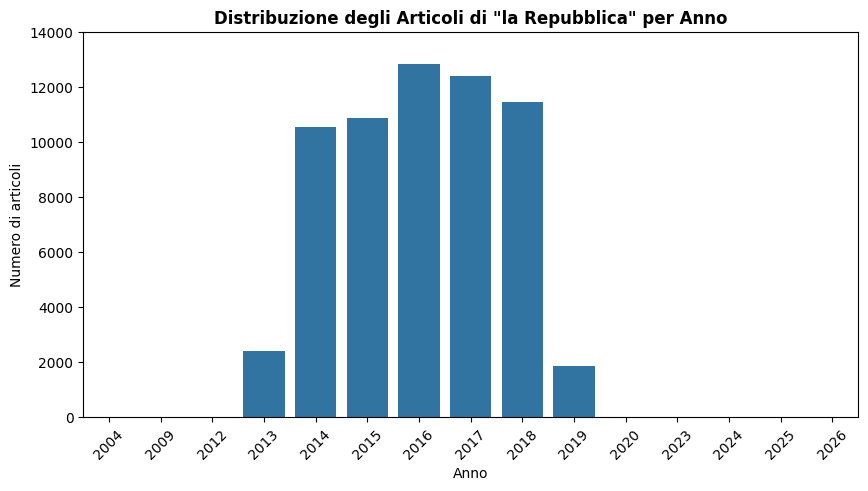

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(data=df_testi_per_anno,
            x="anno",
            y="quantità",
            order=sorted(df_testi_per_anno["anno"].dropna().unique()),
            ax=ax)

ax.set_xlabel("Anno")
ax.set_ylabel("Numero di articoli")
ax.set_title("Distribuzione degli Articoli di \"la Repubblica\" per Anno", fontweight="bold")

ax.set_ylim(0, 14000) #setta un limite dell'asse y

plt.xticks(rotation=45)  #ruota gli indici dell'asse x di 45 gradi
plt.show()

*Il grafico mostra una concentrazione degli articoli tra il 2013 e il 2019, con un picco nel 2016. Questo giustifica la scelta di limitare l'analisi a questo intervallo temporale.*

### **Ricostruzione del dataframe repubblica, tokenizzato e con anno e tipologia in colonne apposite**
*Dataframe che verrà utilizzato per le analisi, dove vengono tolti gli articoli con tipologia "esteri" e con anni esterni al range 2013/2019 compresi. La tipologia esteri viene esclusa per evitare che la politica estera influenzi sensibilmente l'analisi.*

In [12]:
concatenazione = pd.concat([tokenizzazione_headline, tokenizzazione_text, df_anno_tipologia], axis=1)

anni = [str(anno) for anno in range(2013, 2020)]

df_repubblica = concatenazione[(concatenazione["tipologia"] != "esteri") & 
                               (concatenazione["anno"].isin(anni))]

# Controllo lunghezza df senza esteri e testi fuori dal periodo 2013-2019

df_repubblica.head(10)
len(df_repubblica) # 48408
len(df_anno_tipologia[df_anno_tipologia["tipologia"] == "esteri"]) #13919
len(df_anno_tipologia[df_anno_tipologia["tipologia"].isna()]) #1354
df_testi_per_anno["anno"] = df_testi_per_anno["anno"].astype(int)
int(df_testi_per_anno[~df_testi_per_anno["anno"].isin(range(2013, 2020))]["quantità"].sum()) #21

21

## **Dataframe cittadinanza**
*Dato che il totale dei residenti in Italia è preso in esame più volte con divisioni territoriali differenti (comuni, province, regioni, zone geografiche e Italia) a cui corrispondono codici ISTAT diversi, abbiamo controllato che effettivamente i totali di ogni codice fossero gli stessi per procedere con una sola divisione in modo da non contare più volte gli individui.*

#### **Estrazione dataframe dei comuni (codice istat 6 cifre)**

In [13]:
df_cittadinanza_csv["Codice Istat"] = df_cittadinanza_csv["Codice Istat"].str.strip()
df_cittadinanza_comuni = df_cittadinanza_csv[(df_cittadinanza_csv["Codice Istat"].str.len() == 6) & 
                                             (df_cittadinanza_csv["Codice Istat"].str.isdigit())]

df_cittadinanza_comuni["Totale"].sum() # --> 1420525426


np.int64(1420525426)

#### **Estrazione dataframe delle province (codice istat a 3 cifre)**

In [14]:
df_cittadinanza_province = df_cittadinanza_csv[(df_cittadinanza_csv["Codice Istat"].str.len() == 3) &
                                           (df_cittadinanza_csv["Codice Istat"].str.isdigit())]
df_cittadinanza_province["Totale"].sum() # --> 1420525426

np.int64(1420525426)

#### **Estrazione dataframe delle regioni (codice istat 2 cifre)**

In [15]:
df_cittadinanza_regioni = df_cittadinanza_csv[(df_cittadinanza_csv["Codice Istat"].str.len() == 2) &
                                              (df_cittadinanza_csv["Codice Istat"].str.isdigit())]
df_cittadinanza_regioni.sort_values("Codice Istat")
df_cittadinanza_regioni["Totale"].sum() # --> 1420525426

np.int64(1420525426)

#### **Estrazione dataframe delle ripartizioni territoriali (codice istat 1 cifra)**

In [16]:
df_cittadinanza_ripartizioni = df_cittadinanza_csv[
    (df_cittadinanza_csv["Codice Istat"].str.len() == 1) &
    (df_cittadinanza_csv["Codice Istat"].str.isdigit())] 
df_cittadinanza_ripartizioni["Totale"].sum() # --> 1420525426

np.int64(1420525426)

#### **Estrazione dataframe codice IT**

In [17]:
df_cittadinanza_IT = df_cittadinanza_csv[df_cittadinanza_csv["Codice Istat"] == "IT"]
df_cittadinanza_IT.sort_values("Codice Istat")
df_cittadinanza_IT["Totale"].sum() # --> 1420525426

np.int64(1420525426)

#### **Controllo lunghezza dataframe**

In [18]:
somma_totale = (len(df_cittadinanza_comuni)
                + len(df_cittadinanza_province)
                + len(df_cittadinanza_regioni)
                + len(df_cittadinanza_ripartizioni)
                + len(df_cittadinanza_IT))

print(len(df_cittadinanza_csv) == somma_totale)

True


#### **Filtraggio dataframe delle nazioni che hanno più cittadini in Italia (anni di interesse 2013-2019)**
*Il dataframe utilizzato è quello dei comuni.*
*In questo passaggio estraiamo le nazionalità demograficamente più rilevanti in Italia nel periodo di indagine. Filtrando i dati ISTAT e aggregando i volumi dei residenti sui sette anni, otteniamo una classifica decrescente delle sole comunità straniere (escludendo il dato totale italiano).*

In [19]:
anni = list(range(2013, 2020))
filtro_anni_comuni = df_cittadinanza_comuni[df_cittadinanza_comuni["Anno"].isin(anni)]
cittadinanze_maggiori = filtro_anni_comuni.groupby("Stato di cittadinanza")["Totale"].sum() 
cittadinanze_maggiori = cittadinanze_maggiori.sort_values(ascending = False).reset_index() 
df_cittadinanze_maggiori = cittadinanze_maggiori.copy()
df_cittadinanze_maggiori.loc[1:10] #Per escludere Italia [0]

,Stato di cittadinanza,Totale
1,Romania,7612895
2,Albania,3190123
3,Marocco,3028658
4,Cina,1787445
5,Ucraina,1530485
6,Filippine,1067945
7,India,974481
8,Moldova,950142
9,Bangladesh,780075
10,Egitto,738601


#### **Definizione delle nazionalità di interesse e filtraggio del dataframe**

In [20]:
stati = ["Romania", "Albania", "Marocco", "Ucraina", "Cina", "Germania"]

df_cittadinanza = df_cittadinanza_comuni[(df_cittadinanza_comuni["Stato di cittadinanza"].isin(stati)) & 
                                         (df_cittadinanza_comuni["Anno"].isin(anni))]
df_cittadinanza

,Anno,Codice Istat,Denominazione,Codice stato di cittadinanza,Stato di cittadinanza,Zona,Continente,Maschi,Femmine,Totale
2325518,2013,001001,Agliè,201,Albania,Europa Centro-Orientale,Europa,8,7,15
2325525,2013,001001,Agliè,314,Cina,Asia Orientale,Asia,24,19,43
2325533,2013,001001,Agliè,436,Marocco,Africa Settentrionale,Africa,13,11,24
2325541,2013,001001,Agliè,235,Romania,Unione Europea,Europa,51,68,119
2325543,2013,001001,Agliè,243,Ucraina,Europa Centro-Orientale,Europa,2,6,8
...,...,...,...,...,...,...,...,...,...,...
3931481,2019,111106,Villasor,235,Romania,Unione Europea,Europa,8,14,22
3931486,2019,111106,Villasor,243,Ucraina,Europa Centro-Orientale,Europa,1,4,5
3931499,2019,111107,Villaspeciosa,436,Marocco,Africa Settentrionale,Africa,4,11,15
3931502,2019,111107,Villaspeciosa,235,Romania,Unione Europea,Europa,1,6,7


#### **Grafico del numero di residenti delle cittadinanze di interesse dal 2013 al 2019**

In [21]:
cittadinanze_anno = (df_cittadinanza
                     .groupby(["Stato di cittadinanza", "Anno"])
                     ["Totale"].sum().reset_index())

cittadinanze_anno.head(10)

,Stato di cittadinanza,Anno,Totale
0,Albania,2013,483131
1,Albania,2014,488125
2,Albania,2015,484482
3,Albania,2016,455341
4,Albania,2017,433250
5,Albania,2018,422582
6,Albania,2019,423212
7,Cina,2013,223405
8,Cina,2014,237114
9,Cina,2015,240617


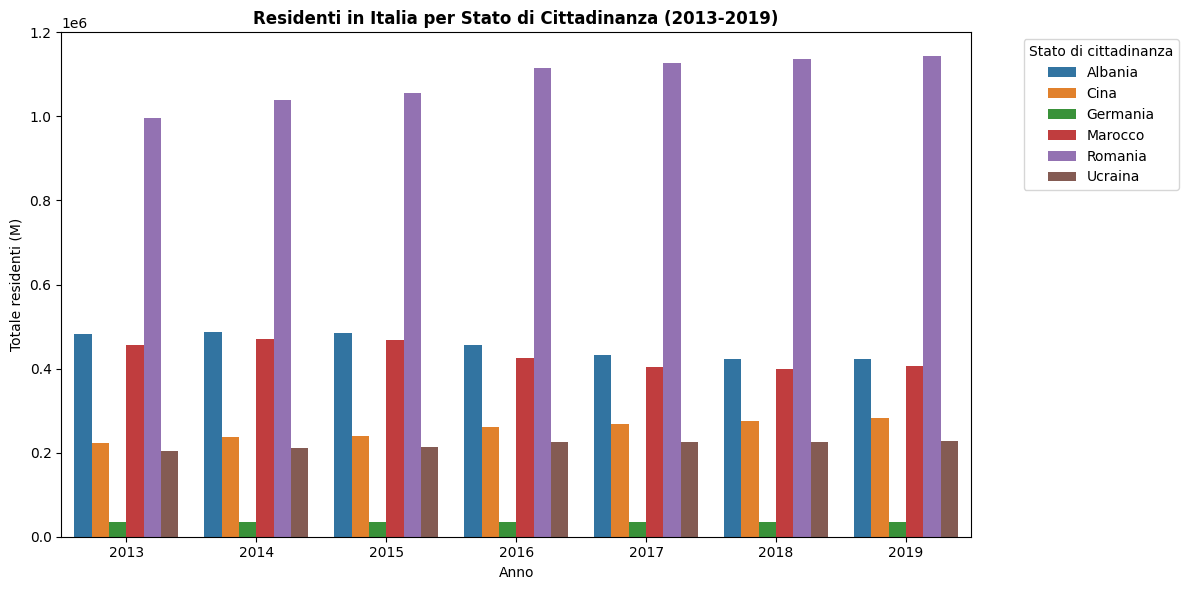

In [22]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(data=cittadinanze_anno,
            x="Anno",
            y="Totale",
            hue="Stato di cittadinanza",
            ax=ax)

ax.set_ylim(0, 1200000)
ax.set_title("Residenti in Italia per Stato di Cittadinanza (2013-2019)", fontweight="bold")
ax.set_xlabel("Anno")
ax.set_ylabel("Totale residenti (M)")

plt.legend(title="Stato di cittadinanza", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

*Il grafico mostra la distribuzione dei residenti stranieri in Italia per le sei nazionalità selezionate nel periodo 2013-2019.* 
- *La comunità rumena è di gran lunga la più numerosa, con circa 1 milione di residenti nel 2013 che crescono fino a stabilizzarsi intorno a 1,15 milioni dal 2016 in poi.* 
- *Albania e Marocco si collocano su livelli simili (~400.000-500.000), con un lieve calo dell'Albania nel tempo.*
- *La Cina mostra una crescita costante da circa 220.000 a quasi 290.000 residenti.*
- *Ucraina e Germania sono le comunità meno numerose del gruppo, rispettivamente intorno a 220.000 e 30.000 residenti.*

# **ANALISI DEI DATI**:
*Dataframe utilizzati da qui in poi:*
- *`df_repubblica`: articoli di "la Repubblica" tokenizzati, senza esteri, nel periodo 2013-2019;*
- *`df_cittadinanza`: dati ISTAT per cittadinanza, solo comuni, nel periodo 2013-2019, filtrati sulle nazioni presenti in `stati`.*

# **1. Quanto spazio mediatico? L'indice di sovrarappresentazione**
*L’indice di sovrarappresentazione confronta il peso demografico di una nazionalità sul totale dei residenti con la sua presenza nei testi analizzati. Serve a verificare se una nazionalità è rappresentata nei testi in modo proporzionato, superiore o inferiore rispetto alla sua incidenza reale nella popolazione.
Valori inferiori a 1 indicano sottorappresentazione, valori intorno a 1 indicano una rappresentazione proporzionata, mentre valori superiori a 1 indicano sovrarappresentazione.*

#### **Ricerca di tutti gli articoli che citano le nazionalità di interesse**

*In questo passaggio procediamo a isolare gli articoli che parlano delle comunità straniere selezionate. Utilizzando un dizionario basato su espressioni regolari (RegEx), il codice scansiona il testo pulito alla ricerca delle radici linguistiche legate a ciascuna cittadinanza (es. "rumen", "albanes").*

In [23]:
# Uso df_repubblica: contiene articoli non esteri del periodo 2013-2019.
articoli_periodo = df_repubblica.copy()

# Conteggio globale degli articoli per anno.
articoli_per_anno = (articoli_periodo
                   .groupby("anno")
                   .size() 
                   .reset_index(name="articoli_totali")) 

regex_nazionalita = {"Romania": r"\bromen[aoie]\b|\brumen[aoie]\b",
                     "Albania": r"\balbanes[ie]\b",
                     "Marocco": r"\bmarocchin[aoie]\b",
                     "Ucraina": r"\bucrain[aoie]\b",
                     "Cina": r"\bcines[ei]\b",
                     "Germania": r"\btedesc[ao]\b|\btedesch[ie]\b"}

lista_articoli_nazionalità = []

for nazionalita, regex in regex_nazionalita.items():
    df = articoli_periodo[articoli_periodo["text_tokenizzato"]
                          .str
                          .contains(regex, regex=True, na=False)].copy()
    df["nazionalità"] = nazionalita
    lista_articoli_nazionalità.append(df)

df_articoli_nazionalita = pd.concat(lista_articoli_nazionalità, ignore_index = True)
df_articoli_nazionalita

,headline_tokenizzata,text_tokenizzato,anno,tipologia,nazionalità
0,per cacciare degli stranieri diede fuoco alla ...,reggio calabria non li sopportava non voleva v...,2018,cronaca,Romania
1,terni bambino di 6 anni violentato da madre e ...,terni e stata una segnalazione a permettere al...,2016,cronaca,Romania
2,tradito da tutti l ultima reggia dello zar un ...,pskov l ultima reggia dell ultimo zar nell ult...,2017,cultura,Romania
3,latina quei profughi dell est dimenticati e sp...,c era una volta il campo profughi rossi longhi...,2015,cultura,Romania
4,la corte di strasburgo autorizza le aziende a ...,mail e messaggi via chat controllati dai dator...,2016,tecnologia,Romania
...,...,...,...,...,...
4907,nsa quei meeting segreti con google co le rela...,non è più alla guida della national security a...,2014,tecnologia,Germania
4908,vertice bruxelles pronta la carta enrico letta,bruxelles sotto una pioggerella autunnale i le...,2014,speciali,Germania
4909,maltempo 12 morti a maiorca disperso un bambino,è di 12 morti e un bambino disperso il bilanci...,2018,cronaca,Germania
4910,berlino a fumetti tra suggestioni e quotidiano...,un italiano a parigi disegna un italiano a ber...,2014,cultura,Germania


In [24]:
gruped_anno_nazionalità = df_articoli_nazionalita.groupby(["anno", "nazionalità"]).size()
gruped_anno_nazionalità.name = "Quantità di articoli"
gruped_anno_nazionalità = gruped_anno_nazionalità.reset_index()
gruped_anno_nazionalità

,anno,nazionalità,Quantità di articoli
0,2013,Albania,9
1,2013,Cina,59
2,2013,Germania,81
3,2013,Marocco,13
4,2013,Romania,16
5,2013,Ucraina,11
6,2014,Albania,33
7,2014,Cina,172
8,2014,Germania,473
9,2014,Marocco,44


### **Calcolo peso mediatico**
*Per peso mediatico si intende la quota percentuale di articoli che menzionano una specifica nazionalità in un determinato anno rispetto al totale degli articoli pubblicati nello stesso anno.*

In [25]:
articoli_totali = df_repubblica.groupby("anno").size()
articoli_totali.name = "Articoli_anno"
articoli_totali = articoli_totali.reset_index()
articoli_totali
peso_mediatico = gruped_anno_nazionalità.merge(articoli_totali, on = "anno")
peso_mediatico["peso_mediatico"] = (peso_mediatico["Quantità di articoli"] / peso_mediatico["Articoli_anno"] * 100).round(3)
peso_mediatico = peso_mediatico.sort_values(["nazionalità", "anno"]).reset_index(drop = True)
peso_mediatico

,anno,nazionalità,Quantità di articoli,Articoli_anno,peso_mediatico
0,2013,Albania,9,1792,0.502
1,2014,Albania,33,8163,0.404
2,2015,Albania,47,8191,0.574
3,2016,Albania,68,10037,0.677
4,2017,Albania,57,9538,0.598
5,2018,Albania,36,9138,0.394
6,2019,Albania,3,1549,0.194
7,2013,Cina,59,1792,3.292
8,2014,Cina,172,8163,2.107
9,2015,Cina,207,8191,2.527


#### **Calcolo dell’incidenza demografica di una cittadinanza**
*Indica il peso percentuale dei residenti appartenenti a quella cittadinanza rispetto al totale dei residenti in Italia nello stesso anno.*

*Il denominatore include anche i cittadini italiani poiché il peso mediatico è calcolato sul totale degli articoli, che non si limitano a trattare tematiche legate agli stranieri. In questo modo i due indicatori condividono lo stesso denominatore di riferimento, rendendo il confronto coerente.*

In [26]:
totale_annuale_residenti = (df_cittadinanza_comuni
                            .groupby("Anno")["Totale"]
                            .sum()
                            .reset_index(name="totale_residenti"))

totale_annuale_residenti = totale_annuale_residenti[totale_annuale_residenti["Anno"].isin(range(2013, 2020))]
totale_annuale_residenti = totale_annuale_residenti.reset_index(drop = True)
totale_annuale_residenti

,Anno,totale_residenti
0,2013,60277309
1,2014,60345917
2,2015,60295497
3,2016,60163712
4,2017,60066734
5,2018,59937769
6,2019,59816673


In [27]:
presenza_demografica = df_cittadinanza.groupby(["Stato di cittadinanza", "Anno"])["Totale"].sum()
presenza_demografica = presenza_demografica.reset_index()

presenza_demografica = presenza_demografica.merge(totale_annuale_residenti, on = "Anno")
presenza_demografica["incidenza demografica %"] = (presenza_demografica["Totale"] / presenza_demografica["totale_residenti"] * 100).round(3)
presenza_demografica

,Stato di cittadinanza,Anno,Totale,totale_residenti,incidenza demografica %
0,Albania,2013,483131,60277309,0.802
1,Albania,2014,488125,60345917,0.809
2,Albania,2015,484482,60295497,0.804
3,Albania,2016,455341,60163712,0.757
4,Albania,2017,433250,60066734,0.721
5,Albania,2018,422582,59937769,0.705
6,Albania,2019,423212,59816673,0.708
7,Cina,2013,223405,60277309,0.371
8,Cina,2014,237114,60345917,0.393
9,Cina,2015,240617,60295497,0.399


#### **Calcolo indice di sovrarappresentazione mediatica negli anni di riferimento**

*L'indice di sovrarappresentazione mediatica viene comunemente calcolato attraverso il rapporto tra la percentuale di visibilità mediatica di un gruppo (peso_mediatico) e la sua percentuale di incidenza demografica sul totale.*

In [28]:
peso_mediatico["anno"] = peso_mediatico["anno"].astype(int)

df_indice_sovrarappresentazione = presenza_demografica.merge(peso_mediatico[["anno", "nazionalità", "peso_mediatico"]],
                                     left_on=["Anno", "Stato di cittadinanza"],
                                     right_on=["anno", "nazionalità"],
                                     how="left")

df_indice_sovrarappresentazione = df_indice_sovrarappresentazione.drop(columns=["anno", "nazionalità"])

df_indice_sovrarappresentazione["indice_di_sovrarappresentazione"] = (df_indice_sovrarappresentazione["peso_mediatico"] /
                                                                      df_indice_sovrarappresentazione["incidenza demografica %"]).round(3)

df_indice_sovrarappresentazione 

,Stato di cittadinanza,Anno,Totale,totale_residenti,incidenza demografica %,peso_mediatico,indice_di_sovrarappresentazione
0,Albania,2013,483131,60277309,0.802,0.502,0.626
1,Albania,2014,488125,60345917,0.809,0.404,0.499
2,Albania,2015,484482,60295497,0.804,0.574,0.714
3,Albania,2016,455341,60163712,0.757,0.677,0.894
4,Albania,2017,433250,60066734,0.721,0.598,0.829
5,Albania,2018,422582,59937769,0.705,0.394,0.559
6,Albania,2019,423212,59816673,0.708,0.194,0.274
7,Cina,2013,223405,60277309,0.371,3.292,8.873
8,Cina,2014,237114,60345917,0.393,2.107,5.361
9,Cina,2015,240617,60295497,0.399,2.527,6.333


### **Controllo degli indici anomali**

*Controlliamo se alcune nazionalità presentano valori particolarmente alti o particolarmente bassi dell'indice di sovrarappresentazione.*

*Questo passaggio è utile perché un indice molto alto non indica automaticamente che il giornale parli molto delle persone residenti in Italia appartenenti a quella cittadinanza. In alcuni casi, infatti, le forme nazionali possono riferirsi anche a stati, governi, economia, sport, cultura, prodotti o lingue.*

*Per esempio:*

- *"cinese" può comparire in espressioni come "governo cinese", "mercato cinese", "azienda cinese"*;
- *"tedesco" può comparire in espressioni come "modello tedesco", "economia tedesca", "squadra tedesca"*;
- *"ucraino" può essere legato a eventi politici o bellici, soprattutto in alcuni anni*;
- *"rumeno" può essere invece molto presente nei dati demografici ma poco visibile negli articoli*.

**Valori maggiori di 5**

In [29]:
indici_sopra_5 = df_indice_sovrarappresentazione[df_indice_sovrarappresentazione["indice_di_sovrarappresentazione"] > 5]
indici_sopra_5 = indici_sopra_5.reset_index(drop=True)
indici_sopra_5

,Stato di cittadinanza,Anno,Totale,totale_residenti,incidenza demografica %,peso_mediatico,indice_di_sovrarappresentazione
0,Cina,2013,223405,60277309,0.371,3.292,8.873
1,Cina,2014,237114,60345917,0.393,2.107,5.361
2,Cina,2015,240617,60295497,0.399,2.527,6.333
3,Cina,2016,260020,60163712,0.432,3.118,7.218
4,Cina,2017,268641,60066734,0.447,2.894,6.474
5,Cina,2018,274218,59937769,0.458,2.605,5.688
6,Cina,2019,283430,59816673,0.474,2.970,6.266
7,Germania,2013,35867,60277309,0.060,4.520,75.333
8,Germania,2014,35691,60345917,0.059,5.794,98.203
9,Germania,2015,34893,60295497,0.058,4.688,80.828


**Valori compresi fra 1 e 5**

In [30]:
indici_fra_1_e_5 = df_indice_sovrarappresentazione[(df_indice_sovrarappresentazione["indice_di_sovrarappresentazione"] > 1) & 
                                                   (df_indice_sovrarappresentazione["indice_di_sovrarappresentazione"] < 5)]
indici_fra_1_e_5 = indici_fra_1_e_5.reset_index(drop=True)
indici_fra_1_e_5

,Stato di cittadinanza,Anno,Totale,totale_residenti,incidenza demografica %,peso_mediatico,indice_di_sovrarappresentazione
0,Marocco,2015,468555,60295497,0.777,0.879,1.131
1,Marocco,2019,406112,59816673,0.679,0.968,1.426
2,Ucraina,2013,203595,60277309,0.338,0.614,1.817
3,Ucraina,2014,209891,60345917,0.348,1.703,4.894
4,Ucraina,2015,212582,60295497,0.353,1.111,3.147
5,Ucraina,2016,224400,60163712,0.373,1.046,2.804
6,Ucraina,2017,225700,60066734,0.376,0.818,2.176
7,Ucraina,2018,226450,59937769,0.378,0.569,1.505
8,Ucraina,2019,227867,59816673,0.381,0.581,1.525


**Valori inferiori a 0.8**

In [31]:
indici_sotto_08 = df_indice_sovrarappresentazione[df_indice_sovrarappresentazione["indice_di_sovrarappresentazione"] < 0.8]
indici_sotto_08 = indici_sotto_08.reset_index(drop=True)
indici_sotto_08

,Stato di cittadinanza,Anno,Totale,totale_residenti,incidenza demografica %,peso_mediatico,indice_di_sovrarappresentazione
0,Albania,2013,483131,60277309,0.802,0.502,0.626
1,Albania,2014,488125,60345917,0.809,0.404,0.499
2,Albania,2015,484482,60295497,0.804,0.574,0.714
3,Albania,2018,422582,59937769,0.705,0.394,0.559
4,Albania,2019,423212,59816673,0.708,0.194,0.274
5,Marocco,2014,469465,60345917,0.778,0.539,0.693
6,Marocco,2016,424093,60163712,0.705,0.359,0.509
7,Marocco,2017,404891,60066734,0.674,0.430,0.638
8,Marocco,2018,398652,59937769,0.665,0.503,0.756
9,Romania,2013,996526,60277309,1.653,0.893,0.540


*Dal controllo degli indici emergono tre situazioni diverse:*

*1. Germania e Cina hanno indici molto alti, ma sono casi problematici perché le forme "tedesco" e "cinese" possono riferirsi a stati, governi, economia, prodotti, lingua o cultura, non necessariamente a persone residenti in Italia.*

*2. L'Ucraina presenta valori superiori a 1 in tutti gli anni, con un picco nel 2014. Questo suggerisce una maggiore visibilità mediatica legata probabilmente a eventi storici e politici di quell'anno.*

*3. Romania e Albania risultano quasi sempre sotto-rappresentate: pur avendo una presenza demografica rilevante, compaiono poco negli articoli.*

## **Euristica: filtraggio dei contesti non personali**
*Sebbene il rischio di usi non personali sia più evidente per Germania e Cina, si è scelto di applicare l'euristica a tutte le nazionalità in modo uniforme. Questo garantisce coerenza metodologica e permette di ottenere una stima più prudente della visibilità mediatica per ciascun gruppo.*

*Per distinguere gli articoli che parlano di "persone fisiche" da quelli che trattano questioni macroeconomiche o geopolitiche, abbiamo costruito un filtro euristico basato su dizionari lessicali mirati. La scelta dei termini non è casuale, ma risponde a due precise logiche di classificazione:*

* **Il vocabolario "Persona":** *Questa lista è stata strutturata per intercettare la dimensione umana a 360 gradi. Include categorie demografiche (età, genere, legami familiari), ruoli sociali e professionali (lavoratori, studenti, medici) e status civili o migratori (cittadini, immigrati, profughi). L'obiettivo è catturare ogni sfumatura della vita quotidiana e dell'integrazione degli individui nella società.*

* **I vocabolari "Non-Persona" (specifici per nazione):** *Per filtrare il "rumore di fondo" e scartare gli articoli in cui la nazione è intesa come Stato e non come comunità umana, abbiamo creato liste di esclusione personalizzate. Oltre a termini istituzionali universali (governo, ambasciata, borsa, export), abbiamo inserito le entità specifiche che dominano il racconto mediatico di ogni singolo Paese (es. la leadership di Merkel o le case automobilistiche per la Germania; la guerra, Putin e Zelensky per l'Ucraina; i colossi tecnologici per la Cina). Questi termini ci permettono di isolare e scartare la cronaca internazionale e finanziaria.*


In [32]:
parole_persona = ["uomo", "uomini", "donna", "donne",
                  "ragazzo", "ragazza", "ragazzi", "ragazze",
                  "giovane", "giovani",
                  "anziano", "anziana", "anziani", "anziane",
                  "cittadino", "cittadina", "cittadini", "cittadine",
                  "residente", "residenti",
                  "abitante", "abitanti",
                  "comunita", "comunità",
                  "famiglia", "famiglie",
                  "lavoratore", "lavoratrice", "lavoratori", "lavoratrici",
                  "operaio", "operaia", "operai", "operaie",
                  "imprenditore", "imprenditrice", "imprenditori", "imprenditrici",
                  "commerciante", "commercianti",
                  "negoziante", "negozianti",
                  "dipendente", "dipendenti",
                  "colf", "badante", "badanti",
                  "studente", "studentessa", "studenti", "studentesse",
                  "ricercatore", "ricercatrice", "ricercatori", "ricercatrici",
                  "professore", "professoressa", "professori", "professoresse",
                  "insegnante", "insegnanti",
                  "turista", "turisti", "turiste",
                  "immigrato", "immigrata", "immigrati", "immigrate",
                  "migrante", "migranti",
                  "straniero", "straniera", "stranieri", "straniere",
                  "profugo", "profuga", "profughi", "profughe",
                  "rifugiato", "rifugiata", "rifugiati", "rifugiate",
                  "persona", "persone",
                  "madre", "madri", "padre", "padri",
                  "figlio", "figlia", "figli", "figlie",
                  "bambino", "bambina", "bambini", "bambine",
                  "minore", "minori",
                  "minorenne", "maggiorenne",
                  "atleta", "atleti", "atlete",
                  "giocatore", "giocatrice", "giocatori", "giocatrici",
                  "calciatore", "calciatrice", "calciatori", "calciatrici",
                  "campione", "campionessa", "campioni", "campionesse",
                  "artista", "artisti", "artiste",
                  "scrittore", "scrittrice", "scrittori", "scrittrici",
                  "attore", "attrice", "attori", "attrici",
                  "regista", "registi",
                  "musicista", "musicisti",
                  "medico", "medica", "medici",
                  "paziente", "pazienti",
                  "vittima", "vittime",
                  "arrestato", "arrestata", "arrestati", "arrestate",
                  "indagato", "indagata", "indagati", "indagate",
                  "detenuto", "detenuta", "detenuti", "detenute"]

forme_cina = ["cinese", "cinesi"]
forme_germania = ["tedesco", "tedesca", "tedeschi", "tedesche"]
forme_marocco = ["marocchino", "marocchina", "marocchini", "marocchine"]
forme_albania = ["albanese", "albanesi"]
forme_ucraina = ["ucraino", "ucraina", "ucraini", "ucraine"]
forme_romania = ["romeno", "romena", "romeni", "romene", "rumeno", "rumena", "rumeni", "rumene"]

parole_non_persona_cina = ["governo", "presidente", "premier", "regime", "partito",
                           "ministro", "ministri", "autorita", "autorità",
                           "ambasciata", "diplomazia", "diplomatico", "diplomatica",
                           "pechino", "shanghai", "hong", "kong", "taiwan",
                           "economia", "mercato", "mercati", "borsa", "yuan",
                           "export", "import", "commercio",
                           "azienda", "aziende", "industria", "industriale",
                           "fabbrica", "fabbriche", "colosso", "gruppo", "societa", "società",
                           "prodotto", "prodotti", "merci", "made",
                           "tecnologia", "smartphone", "huawei", "alibaba", "app",
                           "internet", "digitale", "elettronica",
                           "lingua", "cucina", "ristorante", "ristoranti",
                           "capodanno", "medicina", "tradizionale",
                           "cinema", "film", "letteratura", "arte", "cultura",
                           "modello", "sistema", "valuta", "moneta",
                           "esercito", "militare", "militari"]

parole_non_persona_germania = ["governo", "presidente", "premier", "ministro", "ministri",
                               "cancelliera", "cancelliere", "merkel", "scholz",
                               "berlino", "bundesbank", "bundestag",
                               "ambasciata", "diplomazia",
                               "economia", "mercato", "mercati", "borsa",
                               "export", "import", "commercio",
                               "azienda", "aziende", "industria", "industriale",
                               "fabbrica", "fabbriche", "colosso", "gruppo", "societa", "società",
                               "modello", "sistema", "welfare", "auto", "automobile", "automobili",
                               "volkswagen", "bmw", "mercedes", "audi", "porsche",
                               "lingua", "letteratura", "filosofia", "cultura",
                               "cinema", "film", "musica",
                               "calcio", "squadra", "squadre", "club", "bundesliga",
                               "nazionale", "campionato",
                               "banca", "banche", "deutsche", "lufthansa"]

parole_non_persona_marocco = ["governo", "presidente", "premier", "ministro", "ministri",
                              "re", "monarchia", "monarca", "rabat", "casablanca",
                              "ambasciata", "diplomazia", "diplomatico", "diplomatica",
                              "economia", "mercato", "mercati", "borsa",
                              "export", "import", "commercio",
                              "azienda", "aziende", "industria", "industriale",
                              "fabbrica", "fabbriche", "gruppo", "societa", "società",
                              "maghreb", "sahara", "saharawi", "polisario",
                              "turismo", "turistico", "turistica",
                              "cultura", "lingua", "cucina", "couscous",
                              "islam", "moschea", "religione",
                              "calcio", "squadra", "nazionale", "campionato"]

parole_non_persona_albania = ["governo", "presidente", "premier", "ministro", "ministri",
                              "tirana", "rama", "berisha",
                              "ambasciata", "diplomazia", "diplomatico", "diplomatica",
                              "economia", "mercato", "mercati",
                              "export", "import", "commercio",
                              "azienda", "aziende", "industria", "industriale",
                              "gruppo", "societa", "società",
                              "balcani", "balcanico", "balcanica",
                              "kosovo", "macedonia", "adriatico",
                              "turismo", "turistico", "turistica",
                              "cultura", "lingua", "musica", "letteratura",
                              "calcio", "squadra", "nazionale", "campionato"]

parole_non_persona_ucraina = ["governo", "presidente", "premier", "ministro", "ministri",
                              "zelensky", "poroshenko", "yanukovich",
                              "kiev", "kyiv", "ambasciata", "diplomazia", "diplomatico", "diplomatica",
                              "guerra", "conflitto", "invasione", "occupazione",
                              "russia", "russo", "russa", "russi", "russe",
                              "putin", "mosca", "cremlino",
                              "crimea", "donbass", "donetsk", "lugansk",
                              "esercito", "militare", "militari", "armi", "missili",
                              "nato", "ue", "europa", "sanzioni",
                              "economia", "mercato", "mercati",
                              "export", "import", "grano", "gas",
                              "cultura", "lingua", "letteratura",
                              "calcio", "squadra", "nazionale", "campionato"]

parole_non_persona_romania = ["governo", "presidente", "premier", "ministro", "ministri",
                              "bucarest", "băsescu", "basescu", "iohannis",
                              "ambasciata", "diplomazia", "diplomatico", "diplomatica",
                              "economia", "mercato", "mercati", "borsa",
                              "export", "import", "commercio",
                              "azienda", "aziende", "industria", "industriale",
                              "fabbrica", "fabbriche", "gruppo", "societa", "società",
                              "ue", "europa", "unione", "europea",
                              "dacia", "auto", "automobile", "automobili",
                              "transilvania", "danubio", "carpazi",
                              "cultura", "lingua", "letteratura", "musica",
                              "calcio", "squadra", "nazionale", "campionato"]

*L'euristica si basa sull'analisi delle parole vicine al termine di nazionalità. Per ogni occorrenza, vengono considerate cinque parole precedenti e cinque successive.*

*Se nel contesto compaiono parole come “cittadino”, “residente”, “famiglia”, “lavoratore” o “studente”, l’occorrenza viene classificata come riferita a persone. Se invece compaiono parole come “governo”, “mercato”, “lingua”, “azienda”, “modello” o “squadra”, viene classificata come non personale. I casi non riconoscibili vengono classificati come ambigui.*

In [33]:
def classifica_contesto(testo, forme_nazionalita, parole_persona, parole_non_persona):
    parole = testo.split()
    categoria = "ambiguo"
    
    for posizione in range(len(parole)):
        parola = parole[posizione]
        if parola in forme_nazionalita:
            inizio = posizione - 5
            fine = posizione + 6
            if inizio < 0:
                inizio = 0
            if fine > len(parole):
                fine = len(parole)
            contesto = parole[inizio:fine]
            
            for parola_contesto in contesto:
                if parola_contesto in parole_non_persona:
                    categoria = "non_persona"
            
            for parola_contesto in contesto:
                if parola_contesto in parole_persona:
                    categoria = "persona"
    
    return categoria

In [34]:
df_cina = df_repubblica[df_repubblica["text_tokenizzato"].str.contains(r"\bcines[ei]\b", regex=True, na=False)].copy()
df_cina["categoria"] = df_cina["text_tokenizzato"].apply(lambda testo: classifica_contesto(testo,forme_cina,parole_persona,parole_non_persona_cina))
df_cina["Stato di cittadinanza"] = "Cina"
df_cina = df_cina.copy()
df_cina.reset_index(drop=True)

,headline_tokenizzata,text_tokenizzato,anno,tipologia,categoria,Stato di cittadinanza
0,cina ritrovato un dinosauro di specie sconosci...,hanno fatto esplodere un area rocciosa per cos...,2016,scienze,ambiguo,Cina
1,mwc 2018 android go così lo smartphone è più l...,se c e una tendenza nel mezzo del mobile world...,2018,speciali,non_persona,Cina
2,rio spegne le luci sui giochi di bolt e phelps...,rio de janeiro stremati dopo venti giorni su e...,2016,speciali,ambiguo,Cina
3,l economia globale cresce l aumento della co2 ...,roma per la prima volta l economia globale cre...,2015,ambiente,ambiguo,Cina
4,un satellite studierà i terremoti dallo spazio,se una correlazione esiste fra terremoti e per...,2018,scienze,ambiguo,Cina
...,...,...,...,...,...,...
1306,mediapro 50 milioni e il bando ma sky prende t...,diritti tv martedì 27 marzo è un giorno decisi...,2018,rubriche,non_persona,Cina
1307,spazio sulla luna c è un nuovo tipo di roccia,un indizio in più per ricorstruire la storia d...,2015,scienze,ambiguo,Cina
1308,nuovo iphone ipad e poi in tribunale che setti...,tutto nel giro di qualche decina di ore un nuo...,2016,tecnologia,non_persona,Cina
1309,cina viaggio nell universo huawei,shenzhen dimenticate la cina dei prodotti di b...,2016,tecnologia,non_persona,Cina


In [35]:
df_germania = df_repubblica[df_repubblica["text_tokenizzato"].str.contains(r"\btedesc[ao]\b|\btedesch[ie]\b", regex=True, na=False)].copy()
df_germania["categoria"] = df_germania["text_tokenizzato"].apply(lambda testo: classifica_contesto(testo,forme_germania,parole_persona,parole_non_persona_germania))
df_germania["Stato di cittadinanza"] = "Germania"
df_germania = df_germania.copy()
df_germania.reset_index(drop=True)

,headline_tokenizzata,text_tokenizzato,anno,tipologia,categoria,Stato di cittadinanza
0,pordenone ritrovati i tre ragazzi dispersi sul...,andreis pordenone paura e poi sollievo per tre...,2014,cronaca,ambiguo,Germania
1,polverini lo ius soli è una cosa giusta ma sui...,roma dobbiamo rendere più incisiva la nostra o...,2014,politica,non_persona,Germania
2,mattarella ricorda l eccidio di stazzema difen...,sant anna di stazzema è nel cuore degli italia...,2018,politica,ambiguo,Germania
3,l europorcellum da cambiare,ancora non sappiamo come reagiranno i cittadin...,2014,politica,ambiguo,Germania
4,christine macel l arte è sempre arte anche se ...,venezia gli artisti hanno una responsabilità p...,2017,cultura,ambiguo,Germania
...,...,...,...,...,...,...
2312,nsa quei meeting segreti con google co le rela...,non è più alla guida della national security a...,2014,tecnologia,ambiguo,Germania
2313,vertice bruxelles pronta la carta enrico letta,bruxelles sotto una pioggerella autunnale i le...,2014,speciali,ambiguo,Germania
2314,maltempo 12 morti a maiorca disperso un bambino,è di 12 morti e un bambino disperso il bilanci...,2018,cronaca,ambiguo,Germania
2315,berlino a fumetti tra suggestioni e quotidiano...,un italiano a parigi disegna un italiano a ber...,2014,cultura,non_persona,Germania


In [36]:
df_ucraina = df_repubblica[df_repubblica["text_tokenizzato"].str.contains(r"\bucrain[oa]\b|\bucrain[ie]\b",regex=True,na=False)].copy()
df_ucraina["categoria"] = df_ucraina["text_tokenizzato"].apply(lambda testo: classifica_contesto(testo,forme_ucraina,parole_persona,parole_non_persona_ucraina))
df_ucraina["Stato di cittadinanza"] = "Ucraina"
df_ucraina = df_ucraina.copy()
df_ucraina.reset_index(drop=True)

,headline_tokenizzata,text_tokenizzato,anno,tipologia,categoria,Stato di cittadinanza
0,balotelli s indigna per il senatore nero leghi...,roma balotelli ci mette tre punti esclamativi ...,2018,speciali,ambiguo,Ucraina
1,troppo sangue versato dalla siria alla palesti...,troppo sangue è già stato versato un accorato ...,2016,vaticano,ambiguo,Ucraina
2,cybersicurezza l allarme degli esperti borse m...,st marteen la cybersecurity è come l acqua non...,2017,tecnologia,ambiguo,Ucraina
3,ultras e violenza nell europeo senza lo spirit...,roma austria ungheria contro chi ovviamente un...,2016,speciali,non_persona,Ucraina
4,tintoretto e rubens ostaggio della burocrazia,la rapina al museo tintoretto e mantegna ostag...,2016,cronaca,persona,Ucraina
...,...,...,...,...,...,...
480,twitter ecco come lo usano i leader del mondo ...,non è uno strumento trascurabile non lo è più ...,2015,tecnologia,non_persona,Ucraina
481,chernobyl fa ancora paura esperti chiedono int...,roma la catastrofe di chernobyl non è finita g...,2015,ambiente,non_persona,Ucraina
482,ucraina polonia 0 1 biancorossi secondi c è la...,marsiglia non riesce alla polonia il sorpasso ...,2016,speciali,ambiguo,Ucraina
483,fake news la battaglia di olga yurkova stopfak...,varsavia mia madre è russa ma io non andrei ma...,2017,tecnologia,persona,Ucraina


In [37]:
df_marocco = df_repubblica[df_repubblica["text_tokenizzato"].str.contains(r"\bmarocchin[oa]\b|\bmarocchin[ie]\b",regex=True,na=False)].copy()
df_marocco["categoria"] = df_marocco["text_tokenizzato"].apply(lambda testo: classifica_contesto(testo,forme_marocco,parole_persona,parole_non_persona_marocco))
df_marocco["Stato di cittadinanza"] = "Marocco"
df_marocco = df_marocco.copy()
df_marocco.reset_index(drop=True)

,headline_tokenizzata,text_tokenizzato,anno,tipologia,categoria,Stato di cittadinanza
0,migranti strage in mare i tre superstiti erava...,una strage a bordo di quel gommone naufragato ...,2019,cronaca,ambiguo,Marocco
1,l islam in italia e le moschee in garage il vi...,roma sono invisibili comunicano via internet e...,2015,solidarieta,ambiguo,Marocco
2,muore l ex europarlamentare dacia valent dalle...,e morta a roma all età di 52 anni dacia valent...,2015,politica,ambiguo,Marocco
3,istat nascono sempre meno bambini specie da ge...,roma sempre meno nuovi nati in italia secondo ...,2015,cronaca,ambiguo,Marocco
4,nuovi italiani nel 2017 è record di acquisizio...,roma nel 2017 il numero di acquisizioni di cit...,2018,cronaca,ambiguo,Marocco
...,...,...,...,...,...,...
262,rugby da lampedusa al campionato di c2 la vitt...,roma dedicato a quelli che dicevano impossibil...,2016,rubriche,ambiguo,Marocco
263,memoriale della shoah di milano l accoglienza ...,milano semere tiene per mano i due figli di 4 ...,2015,solidarieta,persona,Marocco
264,yara tracce occultate e silenzi sospetti ecco ...,bergamo c è il mistero di una lettera con mina...,2014,cronaca,persona,Marocco
265,arrestato in sardegna presunto terrorista prep...,è sospettato di aver pianificato un attentato ...,2018,cronaca,persona,Marocco


In [38]:
df_albania = df_repubblica[df_repubblica["text_tokenizzato"].str.contains(r"\balbanes[ei]\b",regex=True,na=False)].copy()
df_albania["categoria"] = df_albania["text_tokenizzato"].apply(lambda testo: classifica_contesto(testo,forme_albania,parole_persona,parole_non_persona_albania))
df_albania["Stato di cittadinanza"] = "Albania"
df_albania = df_albania.copy()
df_albania.reset_index(drop=True)

,headline_tokenizzata,text_tokenizzato,anno,tipologia,categoria,Stato di cittadinanza
0,christine macel l arte è sempre arte anche se ...,venezia gli artisti hanno una responsabilità p...,2017,cultura,persona,Albania
1,l islam in italia e le moschee in garage il vi...,roma sono invisibili comunicano via internet e...,2015,solidarieta,ambiguo,Albania
2,birmania il monaco che sembra aver reincarnato...,rangoon il centro thabarwa sorge oltre il fium...,2016,solidarieta,ambiguo,Albania
3,schuttevaer non abbiamo provato a rubare la no...,roma non sappiamo a chi rispondessero i rimorc...,2014,cronaca,persona,Albania
4,istat nascono sempre meno bambini specie da ge...,roma sempre meno nuovi nati in italia secondo ...,2015,cronaca,ambiguo,Albania
...,...,...,...,...,...,...
248,ricercatori le storie di chi è andato all estero,un napoletano a helsinki l ho promesso non me ...,2016,scuola,persona,Albania
249,caso vu cumprà boldrini contro alfano le parol...,roma in politica come nell informazione la for...,2014,politica,ambiguo,Albania
250,guardami ora non mi fai più paura lucia incont...,pesaro niente è niente quell uomo che è a tre ...,2013,cronaca,ambiguo,Albania
251,nostro figlio ha sbagliato ma chi lo ha ucciso...,milano se nostro figlio ha sbagliato ha sbagli...,2015,cronaca,ambiguo,Albania


In [39]:
df_romania = df_repubblica[df_repubblica["text_tokenizzato"].str.contains(r"\bromen[oa]\b|\bromen[ie]\b|\brumen[oa]\b|\brumen[ie]\b",regex=True,na=False)].copy()
df_romania["categoria"] = df_romania["text_tokenizzato"].apply(lambda testo: classifica_contesto(testo,forme_romania,parole_persona,parole_non_persona_romania))
df_romania["Stato di cittadinanza"] = "Romania"
df_romania = df_romania.copy()
df_romania.reset_index(drop=True)

,headline_tokenizzata,text_tokenizzato,anno,tipologia,categoria,Stato di cittadinanza
0,per cacciare degli stranieri diede fuoco alla ...,reggio calabria non li sopportava non voleva v...,2018,cronaca,persona,Romania
1,terni bambino di 6 anni violentato da madre e ...,terni e stata una segnalazione a permettere al...,2016,cronaca,ambiguo,Romania
2,tradito da tutti l ultima reggia dello zar un ...,pskov l ultima reggia dell ultimo zar nell ult...,2017,cultura,ambiguo,Romania
3,latina quei profughi dell est dimenticati e sp...,c era una volta il campo profughi rossi longhi...,2015,cultura,non_persona,Romania
4,la corte di strasburgo autorizza le aziende a ...,mail e messaggi via chat controllati dai dator...,2016,tecnologia,persona,Romania
...,...,...,...,...,...,...
274,università sorpresa confermata le matricole ri...,roma ora è ufficiale dopo 10 anni di discesa l...,2016,scuola,non_persona,Romania
275,calais a migliaia in attesa dell ultima tappa ...,calais il 29 febbraio il governo francese ha o...,2016,solidarieta,ambiguo,Romania
276,a vela nell egeo inseguendo il canto di europa,content navigation padding 20px 0 0 0 content ...,2017,super8,ambiguo,Romania
277,la piña colada di caroline,ellen degeneres forse la più amata comedian am...,2018,rubriche,ambiguo,Romania


In [40]:
df_euristica = pd.concat([df_cina, df_germania, df_albania, df_marocco, df_romania, df_ucraina], ignore_index=True)
df_euristica[["anno", "Stato di cittadinanza", "categoria", "text_tokenizzato"]].tail(20)
df_euristica = df_euristica.sort_values(["anno", "Stato di cittadinanza"]).reset_index(drop = True)
df_euristica

,headline_tokenizzata,text_tokenizzato,anno,tipologia,categoria,Stato di cittadinanza
0,alunni stranieri non è più boom e la maggioran...,roma cambia la presenza degli alunni stranieri...,2013,scuola,ambiguo,Albania
1,corigliano tu lavori i prendo i soldi dietro i...,corigliano cs la tensione sta crescendo tra it...,2013,solidarieta,non_persona,Albania
2,incidenti sul lavoro muoiono tre operai,roma tre morti in tre incidenti diversi la pia...,2013,cronaca,persona,Albania
3,kosov nessuno ha ancora indagato sugli attacch...,kosovska mitrovica il fiume ibar simbolo della...,2013,solidarieta,ambiguo,Albania
4,blitz internazionale contro il traffico di dro...,pescara l interporto della droga dell eroina s...,2013,cronaca,non_persona,Albania
...,...,...,...,...,...,...
4907,le regole d ingaggio di camila e amanda,cinque anni fa o dieci è lo stesso il tennis f...,2019,rubriche,ambiguo,Ucraina
4908,facebook le regole americane per la pubblicità...,facebook stringerà le maglie della pubblicità ...,2019,tecnologia,ambiguo,Ucraina
4909,gommone affonda in zona sar libica tre morti a...,nel mediterraneo sguarnito di navi di soccorso...,2019,cronaca,ambiguo,Ucraina
4910,facebook rimuove centinaia di pagine legate al...,facebook ha annunciato la chiusura di oltre ce...,2019,tecnologia,ambiguo,Ucraina


In [41]:
conteggio_categorie = (df_euristica.groupby(["Stato di cittadinanza", "categoria"]).size().reset_index(name="numero_articoli"))
conteggio_categorie

,Stato di cittadinanza,categoria,numero_articoli
0,Albania,ambiguo,160
1,Albania,non_persona,18
2,Albania,persona,75
3,Cina,ambiguo,715
4,Cina,non_persona,442
5,Cina,persona,154
6,Germania,ambiguo,1482
7,Germania,non_persona,536
8,Germania,persona,299
9,Marocco,ambiguo,150


*Il conteggio mostra che la maggior parte degli articoli rimane nella categoria "ambiguo". Questo conferma un limite dell'euristica: molte occorrenze non contengono parole-spia sufficienti per stabilire se la nazionalità si riferisca a persone o ad altri ambiti.*

*Tuttavia, permette di isolare un sottoinsieme più prudente di articoli classificati come "persona": 75 per l'Albania, 154 per la Cina, 299 per la Germania, 101 per il Marocco, 99 per la Romania e 72 per l'Ucraina. Questi articoli vengono usati per ricalcolare il peso mediatico filtrato.*

In [42]:
articoli_persona = (df_euristica[df_euristica["categoria"] == "persona"].groupby(["anno", "Stato di cittadinanza"])
                    .size().reset_index(name="articoli_persona"))
articoli_persona

,anno,Stato di cittadinanza,articoli_persona
0,2013,Albania,3
1,2013,Cina,12
2,2013,Germania,7
3,2013,Marocco,5
4,2013,Romania,5
5,2013,Ucraina,3
6,2014,Albania,7
7,2014,Cina,20
8,2014,Germania,44
9,2014,Marocco,19


*Questa tabella mostra, anno per anno, quanti articoli sono stati classificati come riferiti a persone. Ad esempio, per la Cina i valori variano da 7 articoli nel 2019 a 38 nel 2017; per la Germania da 7 articoli nel 2013 a 68 nel 2016.*

*Questi numeri sono molto inferiori rispetto al conteggio grezzo iniziale, segno che una parte consistente delle occorrenze era legata a usi non personali o ambigui.*

In [43]:
articoli_grezzi_anno = (df_articoli_nazionalita.groupby("anno").size().reset_index(name="articoli_grezzi"))
articoli_grezzi_anno["anno"] = articoli_grezzi_anno["anno"].astype(int)

articoli_persona_anno = (articoli_persona.groupby("anno")["articoli_persona"].sum().reset_index(name="articoli_persona"))
articoli_persona_anno["anno"] = articoli_persona_anno["anno"].astype(int)

confronto_euristica_anno = articoli_grezzi_anno.merge(articoli_persona_anno, on="anno")
confronto_euristica_anno["differenza"] = (confronto_euristica_anno["articoli_grezzi"] - confronto_euristica_anno["articoli_persona"])

confronto_euristica_anno

,anno,articoli_grezzi,articoli_persona,differenza
0,2013,189,35,154
1,2014,913,127,786
2,2015,859,144,715
3,2016,1044,158,886
4,2017,985,171,814
5,2018,779,139,640
6,2019,143,26,117


In [44]:
articoli_persona["anno"] = articoli_persona["anno"].astype(int)
articoli_totali["anno"] = articoli_totali["anno"].astype(int)
df_indice_sovrarappresentazione["Anno"] = df_indice_sovrarappresentazione["Anno"].astype(int)

### **Ricalcolo del peso mediatico** 

In [45]:
peso_mediatico_filtrato = articoli_persona.merge(articoli_totali, on="anno", how="left")
peso_mediatico_filtrato["peso_mediatico_con_euristica"] = (peso_mediatico_filtrato["articoli_persona"] /
                                                      peso_mediatico_filtrato["Articoli_anno"] * 100)
peso_mediatico_filtrato

,anno,Stato di cittadinanza,articoli_persona,Articoli_anno,peso_mediatico_con_euristica
0,2013,Albania,3,1792,0.167411
1,2013,Cina,12,1792,0.669643
2,2013,Germania,7,1792,0.390625
3,2013,Marocco,5,1792,0.279018
4,2013,Romania,5,1792,0.279018
5,2013,Ucraina,3,1792,0.167411
6,2014,Albania,7,8163,0.085753
7,2014,Cina,20,8163,0.245008
8,2014,Germania,44,8163,0.539018
9,2014,Marocco,19,8163,0.232758


### **Ricalcolo dell'indice di sovrarappresentazione**

*In questo passaggio misuriamo l'impatto effettivo dell'euristica ricalcolando l'indice di sovrarappresentazione esclusivamente sugli articoli incentrati sulle "persone". Confrontando direttamente questo nuovo indice filtrato con quello grezzo calcolato in precedenza, possiamo quantificare la differenza tra i due valori.*

In [46]:
confronto_euristica = df_indice_sovrarappresentazione.merge(peso_mediatico_filtrato,
                                                            left_on = ["Anno", "Stato di cittadinanza"],
                                                            right_on = ["anno", "Stato di cittadinanza"],
                                                            how = "left")
confronto_euristica["indice_filtrato"] = (confronto_euristica["peso_mediatico_con_euristica"] / confronto_euristica["incidenza demografica %"])
confronto_euristica["differenza_indice"] = (confronto_euristica["indice_filtrato"] - confronto_euristica["indice_di_sovrarappresentazione"])
confronto_euristica = confronto_euristica[["Stato di cittadinanza",
                     "Anno",
                     "peso_mediatico",
                     "incidenza demografica %",
                     "indice_di_sovrarappresentazione",
                     "peso_mediatico_con_euristica",
                     "indice_filtrato",
                     "differenza_indice"]].sort_values(["Stato di cittadinanza", "Anno"])
confronto_euristica = confronto_euristica.rename(columns={
    "peso_mediatico": "peso_mediatico_grezzo",
    "incidenza demografica %": "incidenza demografica",
    "indice_di_sovrarappresentazione": "indice_grezzo",
    "peso_mediatico_con_euristica": "peso_mediatico_filtrato"
})

confronto_euristica


,Stato di cittadinanza,Anno,peso_mediatico_grezzo,incidenza demografica,indice_grezzo,peso_mediatico_filtrato,indice_filtrato,differenza_indice
0,Albania,2013,0.502,0.802,0.626,0.167411,0.208742,-0.417258
1,Albania,2014,0.404,0.809,0.499,0.085753,0.105999,-0.393001
2,Albania,2015,0.574,0.804,0.714,0.207545,0.258140,-0.455860
3,Albania,2016,0.677,0.757,0.894,0.199263,0.263227,-0.630773
4,Albania,2017,0.598,0.721,0.829,0.178234,0.247204,-0.581796
5,Albania,2018,0.394,0.705,0.559,0.109433,0.155224,-0.403776
6,Albania,2019,0.194,0.708,0.274,0.064558,0.091183,-0.182817
7,Cina,2013,3.292,0.371,8.873,0.669643,1.804967,-7.068033
8,Cina,2014,2.107,0.393,5.361,0.245008,0.623430,-4.737570
9,Cina,2015,2.527,0.399,6.333,0.207545,0.520163,-5.812837


*La tabella mostra, per ciascuna nazionalità e anno, il confronto tra l'indice grezzo e l'indice filtrato dall'euristica, insieme alla differenza tra i due valori.*

*Già da questi dati emerge una prima risposta all'interrogativo di partenza: **nessuna nazionalità presenta un indice stabile intorno a 1**, valore che indicherebbe una rappresentazione mediatica proporzionale alla presenza demografica.*

*Questi dati forniscono quindi una prima indicazione che i media non funzionino come uno "specchio" della realtà demografica.*

### **I valori più anomali: Cina e Germania**

*Per valutare visivamente l'effetto dell'euristica, confrontiamo l'andamento dell'indice grezzo e dell'indice filtrato nel tempo per le due nazionalità con i valori più anomali: Cina e Germania.*

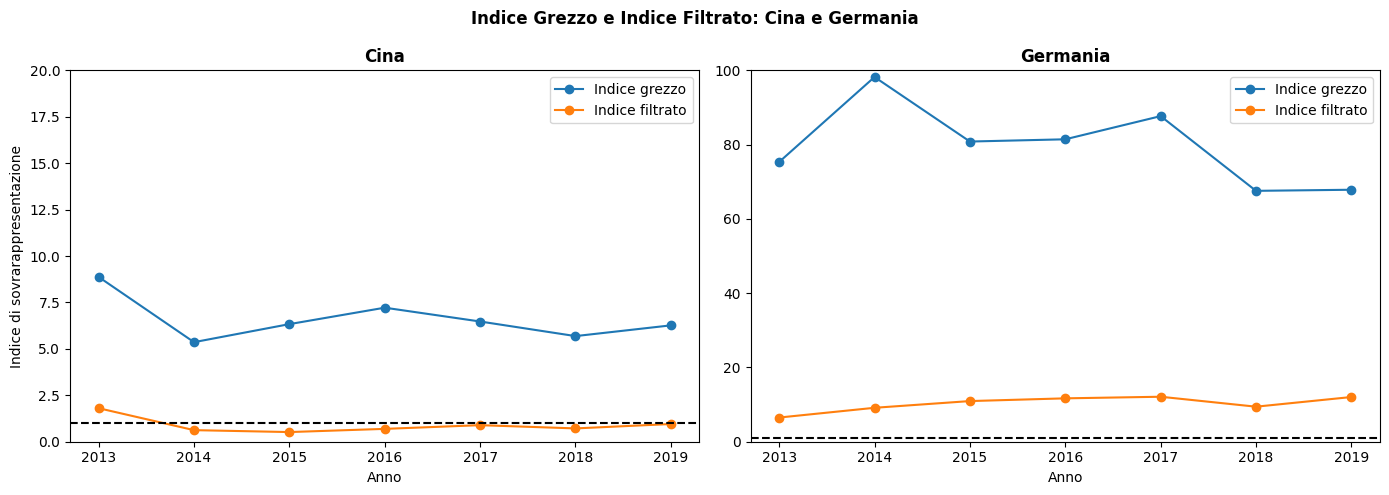

In [47]:
dati_cina = confronto_euristica[confronto_euristica["Stato di cittadinanza"] == "Cina"].sort_values("Anno")
dati_germania = confronto_euristica[confronto_euristica["Stato di cittadinanza"] == "Germania"].sort_values("Anno")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(dati_cina["Anno"], dati_cina["indice_grezzo"], marker="o", label="Indice grezzo")
axes[0].plot(dati_cina["Anno"], dati_cina["indice_filtrato"], marker="o", label="Indice filtrato")
axes[0].axhline(1, color="black", linestyle="--")
axes[0].set_title("Cina", fontweight="bold")
axes[0].set_xlabel("Anno")
axes[0].set_ylabel("Indice di sovrarappresentazione")
axes[0].set_ylim(0, 20)
axes[0].legend()

axes[1].plot(dati_germania["Anno"], dati_germania["indice_grezzo"], marker="o", label="Indice grezzo")
axes[1].plot(dati_germania["Anno"], dati_germania["indice_filtrato"], marker="o", label="Indice filtrato")
axes[1].axhline(1, color="black", linestyle="--")
axes[1].set_title("Germania", fontweight="bold")
axes[1].set_xlabel("Anno")
axes[1].set_ylim(0, 100)
axes[1].legend()

fig.suptitle("Indice Grezzo e Indice Filtrato: Cina e Germania", fontweight="bold")
plt.tight_layout()

plt.show()

*Il confronto tra indice grezzo e indice filtrato mostra l’effetto dell’euristica. Per la Cina l’indice diminuisce drasticamente: in molti anni passa da valori molto superiori a 1 a valori inferiori o vicini a 1. Questo suggerisce che il conteggio grezzo sovrastimava la rappresentazione delle persone cinesi, includendo molti usi relativi a economia, tecnologia, politica, cultura o prodotti.*

*Per la Germania l’indice diminuisce ancora più nettamente, ma resta comunque superiore a 1 in tutti gli anni. Questo suggerisce che anche dopo il filtro la Germania rimane molto visibile rispetto al suo peso demografico, probabilmente perché le persone tedesche compaiono spesso in contesti culturali, politici, sportivi o storici non necessariamente legati alla presenza di residenti tedeschi in Italia.*

*A tal proposito, **l’euristica ha alcuni limiti**. In primo luogo, molti articoli rimangono ambigui perché non contengono parole-spia sufficienti. In secondo luogo, anche quando una menzione viene classificata come “persona”, non è detto che si riferisca a persone residenti in Italia: può trattarsi di turisti, atleti, politici, ricercatori o cittadini di altri paesi. Per questo l’indice filtrato non va interpretato come misura esatta della visibilità dei residenti stranieri, ma come stima più prudente rispetto al conteggio grezzo.*

***L’euristica quindi non elimina tutti i problemi interpretativi, ma mostra che gli indici grezzi erano fortemente influenzati da usi ambigui o non personali delle forme nazionali.***

### **Un caso emblematico: Ucraina 2014**
*È stato dimostrato che l’effetto dell’euristica modifica sensibilmente il valore degli indici di sovrarappresentazione, in alcuni casi in misura rilevante. Per questo motivo è stato scelto un anno emblematico - Ucraina 2014 - in cui l’indice grezzo si discosta in modo significativo dall’indice filtrato.*

In [48]:
confronto_euristica[(confronto_euristica["Stato di cittadinanza"] == "Ucraina") &
                    (confronto_euristica["Anno"] == 2014)]

,Stato di cittadinanza,Anno,peso_mediatico_grezzo,incidenza demografica,indice_grezzo,peso_mediatico_filtrato,indice_filtrato,differenza_indice
36,Ucraina,2014,1.703,0.348,4.894,0.183756,0.528034,-4.365966


*Passando da un valore anomalo di 4.9 a uno di 0.5, l’indice filtrato riporta valori in linea con quelli degli altri anni relativi all’Ucraina. Da ciò emergono due considerazioni:*
- *L’indice grezzo (4.9) risulta più elevato rispetto agli altri anni poiché il giornale trattava l’Ucraina probabilmente in relazione alla guerra e a questioni diplomatiche.*
- *L’indice filtrato suggerisce invece che non vi sia una differenza quantitativa significativa rispetto agli altri anni, da cui si potrebbe inferire che la narrazione sugli ucraini sia rimasta sostanzialmente invariata.*

*Da questa osservazione è nata l’idea di approfondire le tipologie di articoli in cui vengono citati cittadini ucraini nel 2014, per verificare l’eventuale presenza di differenze rispetto agli altri anni.*

In [49]:
df_ucraina = df_ucraina.copy()
df_ucraina.reset_index(drop=True).head()

,headline_tokenizzata,text_tokenizzato,anno,tipologia,categoria,Stato di cittadinanza
0,balotelli s indigna per il senatore nero leghi...,roma balotelli ci mette tre punti esclamativi ...,2018,speciali,ambiguo,Ucraina
1,troppo sangue versato dalla siria alla palesti...,troppo sangue è già stato versato un accorato ...,2016,vaticano,ambiguo,Ucraina
2,cybersicurezza l allarme degli esperti borse m...,st marteen la cybersecurity è come l acqua non...,2017,tecnologia,ambiguo,Ucraina
3,ultras e violenza nell europeo senza lo spirit...,roma austria ungheria contro chi ovviamente un...,2016,speciali,non_persona,Ucraina
4,tintoretto e rubens ostaggio della burocrazia,la rapina al museo tintoretto e mantegna ostag...,2016,cronaca,persona,Ucraina


In [50]:
#teniamo solo le tipologie più frequenti e rilevanti ai fini dell'analisi 
tipologie_rilevanti = ["cronaca", "politica", "solidarieta", "cultura", "tecnologia", "scienze", "ambiente", "salute", "scuola"]
df_confronto_ucraina = df_ucraina[(df_ucraina["categoria"] == "persona") & 
                                  (df_ucraina["tipologia"].isin(tipologie_rilevanti))].copy()
df_confronto_ucraina.reset_index(drop=True).head()

,headline_tokenizzata,text_tokenizzato,anno,tipologia,categoria,Stato di cittadinanza
0,tintoretto e rubens ostaggio della burocrazia,la rapina al museo tintoretto e mantegna ostag...,2016,cronaca,persona,Ucraina
1,inondazione costa azzurra 21 morti anche un it...,nizza il giorno dopo la bomba d acqua che ha c...,2015,cronaca,persona,Ucraina
2,unicef 15 milioni di bambini coinvolti nei con...,roma ben 15 milioni di bambini sono stati coin...,2014,solidarieta,persona,Ucraina
3,abiti puliti quando la schiavitù è made in eur...,roma indossare una maglia comprare un paio di ...,2017,solidarieta,persona,Ucraina
4,istat 15mila nascite in meno in un anno,i dati dell istat contenuti nell ultimo rappor...,2018,cronaca,persona,Ucraina


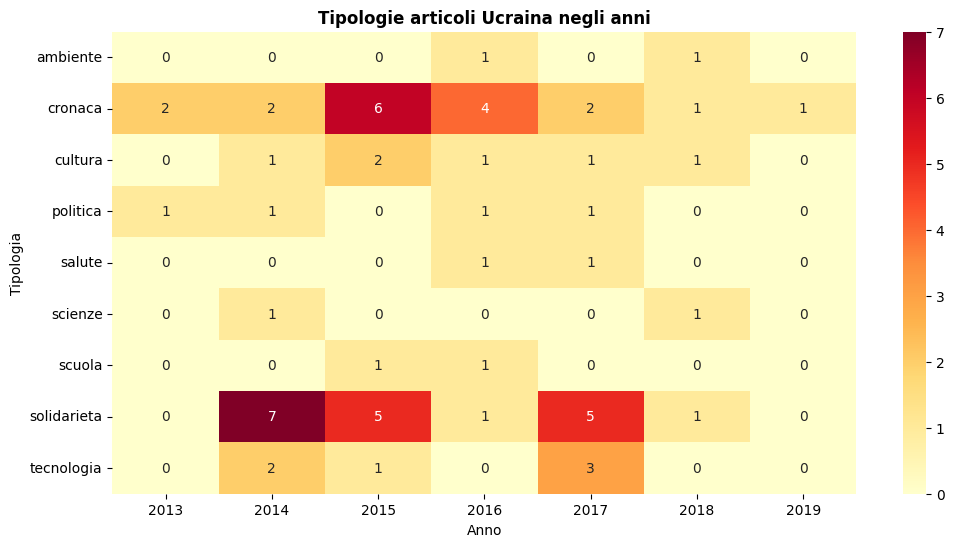

In [51]:
df_cfr_ucraina = df_confronto_ucraina.groupby(["anno", "tipologia"]).size().reset_index(name="quantita")
df_cfr_ucraina["anno"] = df_cfr_ucraina["anno"].astype(int)

heatmap_dati = df_cfr_ucraina.pivot(index="tipologia", columns="anno", values="quantita").fillna(0)

plt.figure(figsize=(12, 6))
sns.heatmap(heatmap_dati, annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("Tipologie articoli Ucraina negli anni", fontweight="bold")
plt.xlabel("Anno")
plt.ylabel("Tipologia")
plt.show()

*Nel passaggio successivo isoliamo il 2014 dal resto del periodo analizzato (2013, 2015-2019). Il codice raggruppa i dati in questi due macro-periodi ("2014" e "altri anni") e calcola l'incidenza percentuale di ciascuna tipologia di articolo sul totale del rispettivo periodo.*

In [52]:
df_confronto_ucraina["periodo"] = "altri anni" 
df_confronto_ucraina.loc[df_confronto_ucraina["anno"].astype(str) == "2014", "periodo"] = "2014"

df_confronto_uc_perc = df_confronto_ucraina.groupby(["periodo", "tipologia"]).size().reset_index(name="quantita") 
df_confronto_uc_perc["totale_periodo"] = df_confronto_uc_perc.groupby("periodo")["quantita"].transform("sum") 
df_confronto_uc_perc["percentuale"] = ((df_confronto_uc_perc["quantita"] / df_confronto_uc_perc["totale_periodo"]) * 100).round(3)
df_confronto_uc_perc

,periodo,tipologia,quantita,totale_periodo,percentuale
0,2014,cronaca,2,14,14.286
1,2014,cultura,1,14,7.143
2,2014,politica,1,14,7.143
3,2014,scienze,1,14,7.143
4,2014,solidarieta,7,14,50.000
5,2014,tecnologia,2,14,14.286
6,altri anni,ambiente,2,47,4.255
7,altri anni,cronaca,16,47,34.043
8,altri anni,cultura,5,47,10.638
9,altri anni,politica,3,47,6.383


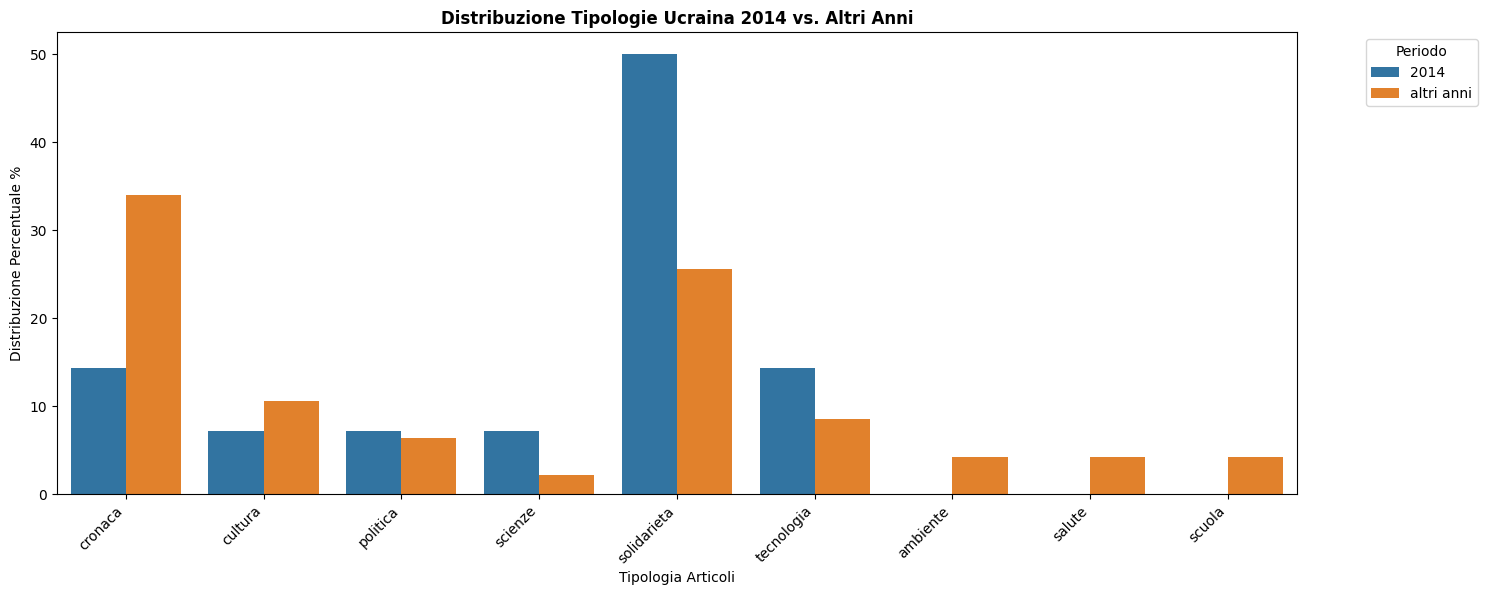

In [53]:
plt.figure(figsize=(16, 6))
sns.barplot(data=df_confronto_uc_perc, x="tipologia", y="percentuale", hue="periodo")
plt.legend(title="Periodo", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.title("Distribuzione Tipologie Ucraina 2014 vs. Altri Anni", fontweight="bold")
plt.xlabel("Tipologia Articoli")
plt.ylabel("Distribuzione Percentuale %")
plt.xticks(rotation=45, ha="right")
plt.show()

*Nel 2014 la rappresentazione delle persone ucraine nei giornali appare fortemente polarizzata verso la solidarietà e il contesto emergenziale, mentre negli altri anni la copertura è più distribuita e “ordinaria”, con maggiore peso della cronaca e una varietà più ampia di temi.*

***Nel 2014, quindi, non cambia l’intensità della presenza delle persone ucraine, ma cambiano sostanzialmente i contesti in cui queste vengono narrate negli articoli.***

## **Correlazione di Pearson**

*Per misurare ulteriormente lo scollamento tra la demografia reale e la narrazione giornalistica, applichiamo il coefficiente di **correlazione di Pearson**.*

*Questo indicatore (compreso tra -1 e +1) misura l'esistenza di un legame matematico tra l'incidenza demografica di una nazionalità e il suo peso mediatico negli anni (2013-2019).*

* *Valori vicini a +1 indicherebbero una maggiore corrispondenza tra andamento demografico e visibilità mediatica.*
* *Valori vicini allo 0 o negativi indicano invece che i giornali seguono criteri editoriali propri e indipendenti (assenza di correlazione o correlazione inversa).*

In [54]:
risultati_correlazione = []

nazioni = confronto_euristica["Stato di cittadinanza"].unique()

for nazione in nazioni:
    df_nazione = confronto_euristica[confronto_euristica["Stato di cittadinanza"] == nazione]
    
    correlazione = df_nazione["incidenza demografica"].corr(df_nazione["peso_mediatico_filtrato"])
    risultati_correlazione.append({"Stato di cittadinanza": nazione,
                                   "Correlazione (Pearson)": round(correlazione, 3)})
    
df_correlazione = pd.DataFrame(risultati_correlazione)
df_correlazione = df_correlazione.sort_values("Correlazione (Pearson)").reset_index(drop=True)

df_correlazione

,Stato di cittadinanza,Correlazione (Pearson)
0,Ucraina,-0.772
1,Germania,-0.679
2,Romania,-0.404
3,Cina,-0.146
4,Albania,0.337
5,Marocco,0.695


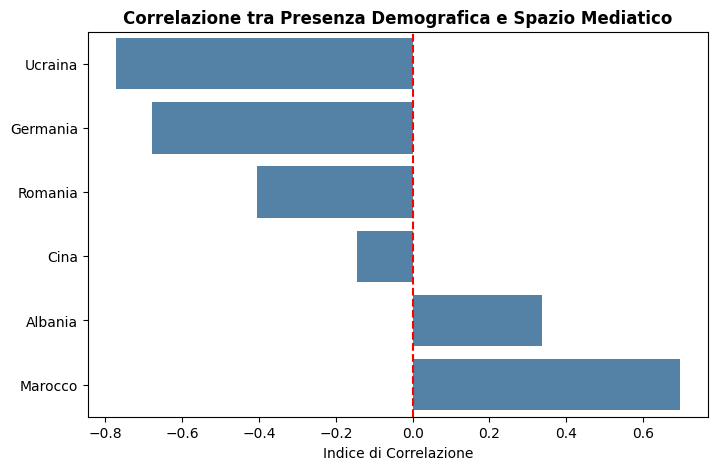

In [55]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df_correlazione, x="Correlazione (Pearson)", y="Stato di cittadinanza", color="steelblue")
plt.axvline(0, color='red', linestyle='--')
plt.title("Correlazione tra Presenza Demografica e Spazio Mediatico", fontweight="bold")
plt.xlabel("Indice di Correlazione")
plt.ylabel("")
plt.show()

### **Interpretazione dei risultati: Il Giornalismo non è uno Specchio**

*I risultati della correlazione offrono ancora una risposta all'interrogativo di partenza: **l'andamento demografico reale non è il motore principale della visibilità mediatica**. I dati suggeriscono, infatti, che per la quasi totalità del campione analizzato il giornalismo non agisce come un semplice "specchio" della realtà demografica, confermando l'influenza di logiche e criteri editoriali autonomi.*

*In particolare, emergono tre dinamiche distinte:*

*1. **La Correlazione Inversa (Ucraina, Germania, Romania):** I valori negativi più forti riguardano l'Ucraina (-0.772) e la Germania (-0.679), seguite dalla Romania (-0.404). Nel caso dell'Ucraina, la correlazione inversa riflette come la visibilità mediatica sia guidata da eventi geopolitici — in particolare la crisi del 2014 — piuttosto che dall'andamento demografico. Per la Germania, dopo il filtraggio dei contesti non personali, emerge che la copertura giornalistica delle persone tedesche residenti in Italia segue criteri editoriali propri, indipendenti dalla loro presenza numerica. La Romania, pur con un valore meno estremo, conferma la tendenza: una comunità che cresce e si stabilizza ottiene meno attenzione mediatica nel tempo.*

*2. **L'Assenza di Correlazione (Cina):** Con un valore prossimo allo zero (-0.146), la Cina non mostra alcun legame tra demografia e visibilità. Anche dopo il filtraggio, la sua presenza nei media appare determinata da fattori esterni alla comunità residente in Italia.*

*3. **Una debole correlazione positiva (Albania e Marocco):** Albania (0.337) e Marocco (0.695) sono le uniche nazionalità con correlazione positiva. Questo non significa necessariamente che i media li rappresentino in modo proporzionato, ma che la loro visibilità mediatica tende a muoversi nella stessa direzione della loro presenza demografica — un risultato che potrebbe essere legato alla forte associazione di queste comunità con temi di cronaca e immigrazione, argomenti che crescono di rilevanza mediatica insieme alla presenza sul territorio.*


# **2. Come vengono raccontati? Analisi del contesto narrativo**

*Analizzando il caso Ucraina 2014, ci si è chiesti se un confronto tra i contesti narrativi in cui vengono citate le persone dei Paesi presi in esame possa fornire indicazioni utili per comprendere come i media le rappresentano.*

*Dopo aver valutato quanto ciascuna nazionalità è rappresentata nei media rispetto al proprio peso demografico, analizziamo ora il “come”: in quali contesti tematici vengono menzionate?*

*Le tipologie di articoli selezionate includono **cronaca, politica, solidarieta, cultura, tecnologia, scienze, ambiente, salute, scuola**. <br> Queste 9 tipologie sono state selezionate perché rappresentano i principali contesti in cui le persone vengono effettivamente citate nei media, coprendo sia l’attualità più frequente (cronaca e politica) sia gli ambiti sociali e di interesse pubblico (salute, scuola, ambiente, scienze, tecnologia). Questa scelta consente quindi di intercettare la grande maggioranza delle menzioni personali. Inoltre, garantisce una classificazione equilibrata dei diversi ruoli in cui gli individui compaiono nel discorso mediatico.*

#### **Ripresa del dataframe filtrato con gli articoli di persona per le nazioni di interesse**


In [56]:
tipologie_rilevanti = ["cronaca","politica","solidarieta","cultura","tecnologia","scienze","ambiente","salute","scuola"]

df_euristica_persona = df_euristica[(df_euristica["categoria"] == "persona") &
                                    (df_euristica["tipologia"].isin(tipologie_rilevanti))].copy()
df_euristica_persona.reset_index(drop=True)

,headline_tokenizzata,text_tokenizzato,anno,tipologia,categoria,Stato di cittadinanza
0,incidenti sul lavoro muoiono tre operai,roma tre morti in tre incidenti diversi la pia...,2013,cronaca,persona,Albania
1,pescina uccide moglie e figlia davanti a un su...,pescina l aquila duplice femminicidio davanti ...,2013,cronaca,persona,Albania
2,infortuni sul lavoro in lombardia uno su 5 rig...,roma un infortunio su cinque in lombardia coin...,2013,solidarieta,persona,Albania
3,forchielli io li conosco gli imprenditori cine...,roma alberto forchielli conosce bene l imprend...,2013,cronaca,persona,Cina
4,niente inglese siamo italiani tutti a lezione ...,siamo tutti russi arabi e cinesi c è francesco...,2013,cronaca,persona,Cina
...,...,...,...,...,...,...
701,bruciarono il clochard per noia il giudice non...,si può uccidere per noia senza trascorrere un ...,2019,cronaca,persona,Marocco
702,mattarella consegna le onorificenze agli eroi ...,il nostro paese è ricco di energie positive di...,2019,cronaca,persona,Romania
703,braccianti sfruttati arresti in calabria immig...,reggio calabria operazione in calabria contro ...,2019,cronaca,persona,Romania
704,veneziano si fingeva chirurgo plastico in roma...,roma non sapeva indossare i guanti in lattice ...,2019,cronaca,persona,Romania


#### **Conteggio della quantità di articoli per una specifica categoria, calcolato per ogni nazione**

In [57]:
conteggi_tipologia = (df_euristica_persona
    .groupby(["Stato di cittadinanza", "tipologia"])
    .size()
    .reset_index(name="articoli_persona"))

conteggi_tipologia.head()

,Stato di cittadinanza,tipologia,articoli_persona
0,Albania,cronaca,42
1,Albania,cultura,5
2,Albania,politica,6
3,Albania,scuola,2
4,Albania,solidarieta,10


#### **Calcolo degli articoli totali per ogni nazionalità filtrati per tipologie rilevanti**

In [58]:
totale_per_nazionalita = conteggi_tipologia.groupby("Stato di cittadinanza")["articoli_persona"].sum()
totale_per_nazionalita = totale_per_nazionalita.reset_index(name= "Totale articoli")
totale_per_nazionalita

,Stato di cittadinanza,Totale articoli
0,Albania,66
1,Cina,140
2,Germania,249
3,Marocco,95
4,Romania,95
5,Ucraina,61


#### **Calcolo della percentuale di incidenza di una tipologia sul totale articoli della nazione in esame**

*Le percentuali sono calcolate sull'intero periodo 2013-2019, aggregando tutti gli anni insieme.*

In [59]:
df_tipologie = conteggi_tipologia.merge(totale_per_nazionalita, on="Stato di cittadinanza", how="left")
df_tipologie["percentuale"] = (df_tipologie["articoli_persona"] / df_tipologie["Totale articoli"] * 100).round(3)
df_tipologie = df_tipologie.sort_values(["Stato di cittadinanza", "percentuale"], ascending=[True, False]).reset_index(drop=True)
df_tipologie.head()

,Stato di cittadinanza,tipologia,articoli_persona,Totale articoli,percentuale
0,Albania,cronaca,42,66,63.636
1,Albania,solidarieta,10,66,15.152
2,Albania,politica,6,66,9.091
3,Albania,cultura,5,66,7.576
4,Albania,scuola,2,66,3.030


#### **Heatmap per evidenziare come le nazionalità siano riportate negli articoli in base alla tipologia**

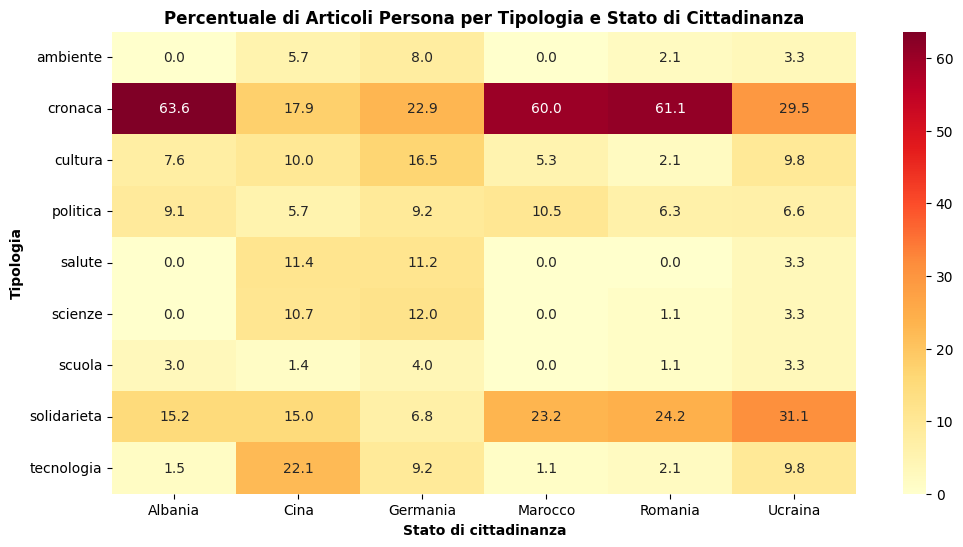

In [60]:
tabella_heatmap_percentuali = df_tipologie.pivot_table(index="tipologia", columns="Stato di cittadinanza",
                                                       values="percentuale", fill_value=0)

plt.figure(figsize=(12, 6))
sns.heatmap(tabella_heatmap_percentuali, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Percentuale di Articoli Persona per Tipologia e Stato di Cittadinanza", fontweight="bold")
plt.xlabel("Stato di cittadinanza", fontweight="bold")
plt.ylabel("Tipologia", fontweight="bold")
plt.show()

*Questo grafico permette di capire concretamente in quali tipi di articoli compaiono le persone delle diverse nazionalità. La mappa mostra tre situazioni molto diverse tra loro:*

*1. **Lo schiacciamento sulla cronaca (Albania, Romania e Marocco):** Per queste tre comunità, la **cronaca** assorbe da sola ben oltre la metà degli articoli (63.6% per l'Albania, 61.1% per la Romania, 60.0% per il Marocco). Questo dato è coerente con quanto osservato in precedenza per il Marocco: la sua correlazione positiva non indica una rappresentazione ideale, ma riflette il fatto che la visibilità di questa comunità è strettamente legata a notizie di cronaca, che tendono ad aumentare con l'aumentare della presenza sul territorio.*

*2. **Il primato della solidarietà (Ucraina):** L'Ucraina rappresenta un caso unico nel dataset. È l'unica nazione in cui la categoria **solidarietà** (31.1%) supera la cronaca (29.5%). Questo dato è coerente con lo stretto legame tra la visibilità di questa comunità e il racconto degli aiuti umanitari, specialmente in concomitanza con la crisi del 2014, spostando l'attenzione del giornale sul tema del supporto e dell'assistenza.*

*3. **Il racconto per temi specifici (Cina e Germania):** Cina e Germania mostrano i livelli di **cronaca** più bassi di tutto il campione (17.9% e 22.9%). Per gli individui di origine cinese emerge una forte associazione con il tema della **tecnologia** (22.1%), mentre per i cittadini tedeschi il racconto si divide tra **cultura** (16.5%), **scienze** (12.0%) e **salute** (11.2%). Queste due nazioni vengono quindi associate dai media a contesti lavorativi, culturali o scientifici, piuttosto che a dinamiche di disagio sociale.*


### **Confronto tra le nazionalità sulla tipologia di articoli**

In [61]:
#ripresa del df_euristica_persona
df_euristica_persona.columns  
df_euristica_persona.reset_index(drop = True)

,headline_tokenizzata,text_tokenizzato,anno,tipologia,categoria,Stato di cittadinanza
0,incidenti sul lavoro muoiono tre operai,roma tre morti in tre incidenti diversi la pia...,2013,cronaca,persona,Albania
1,pescina uccide moglie e figlia davanti a un su...,pescina l aquila duplice femminicidio davanti ...,2013,cronaca,persona,Albania
2,infortuni sul lavoro in lombardia uno su 5 rig...,roma un infortunio su cinque in lombardia coin...,2013,solidarieta,persona,Albania
3,forchielli io li conosco gli imprenditori cine...,roma alberto forchielli conosce bene l imprend...,2013,cronaca,persona,Cina
4,niente inglese siamo italiani tutti a lezione ...,siamo tutti russi arabi e cinesi c è francesco...,2013,cronaca,persona,Cina
...,...,...,...,...,...,...
701,bruciarono il clochard per noia il giudice non...,si può uccidere per noia senza trascorrere un ...,2019,cronaca,persona,Marocco
702,mattarella consegna le onorificenze agli eroi ...,il nostro paese è ricco di energie positive di...,2019,cronaca,persona,Romania
703,braccianti sfruttati arresti in calabria immig...,reggio calabria operazione in calabria contro ...,2019,cronaca,persona,Romania
704,veneziano si fingeva chirurgo plastico in roma...,roma non sapeva indossare i guanti in lattice ...,2019,cronaca,persona,Romania


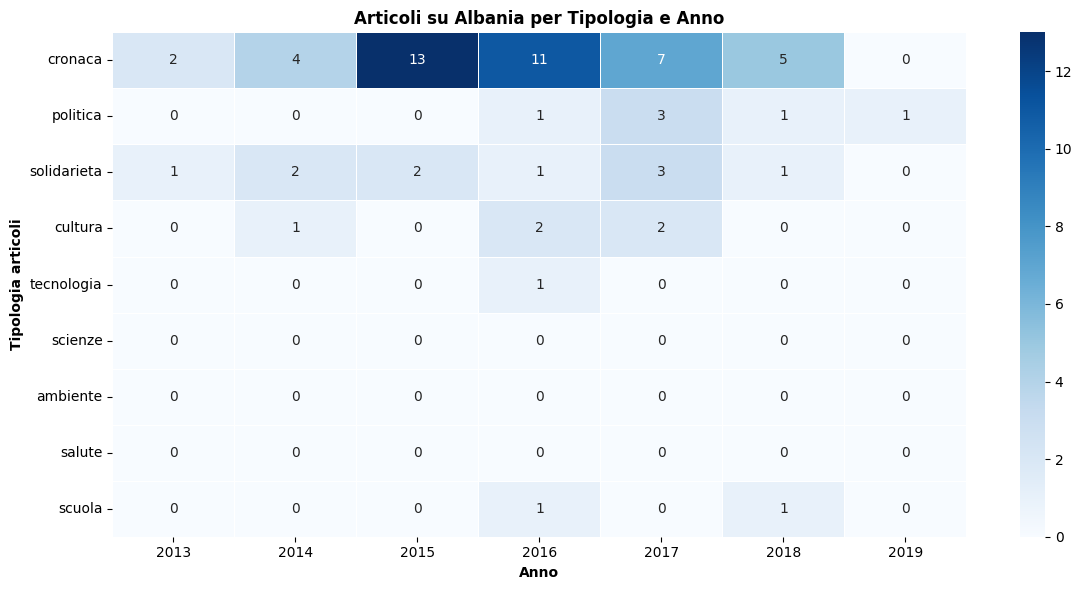

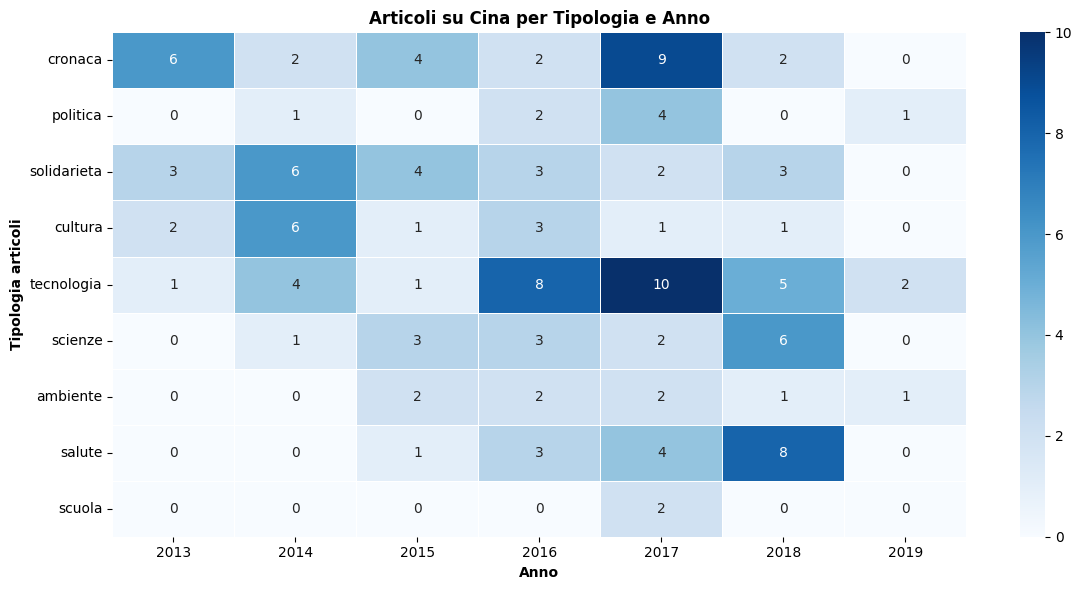

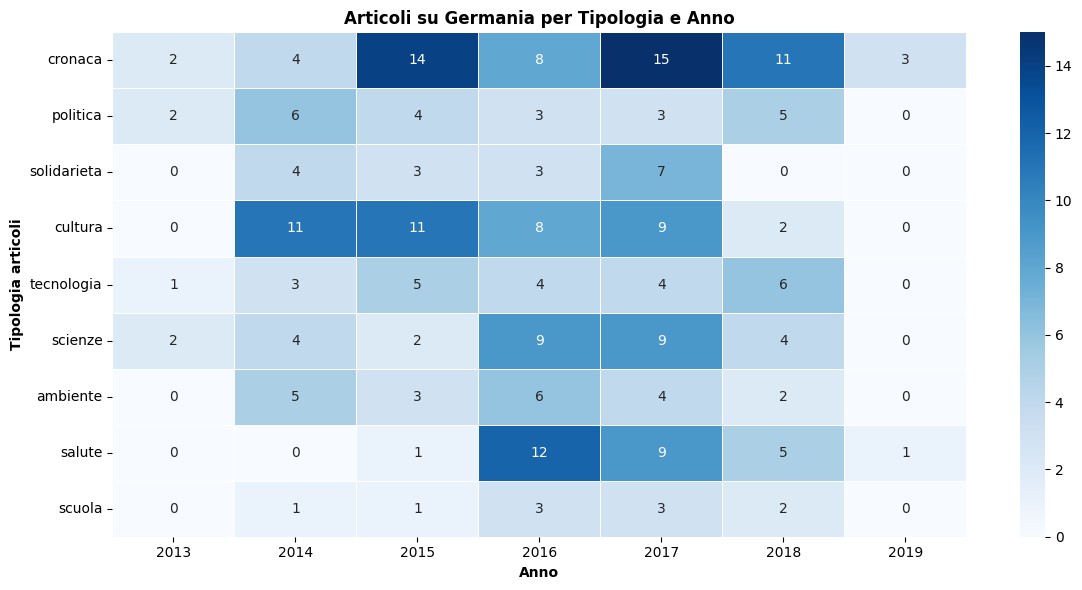

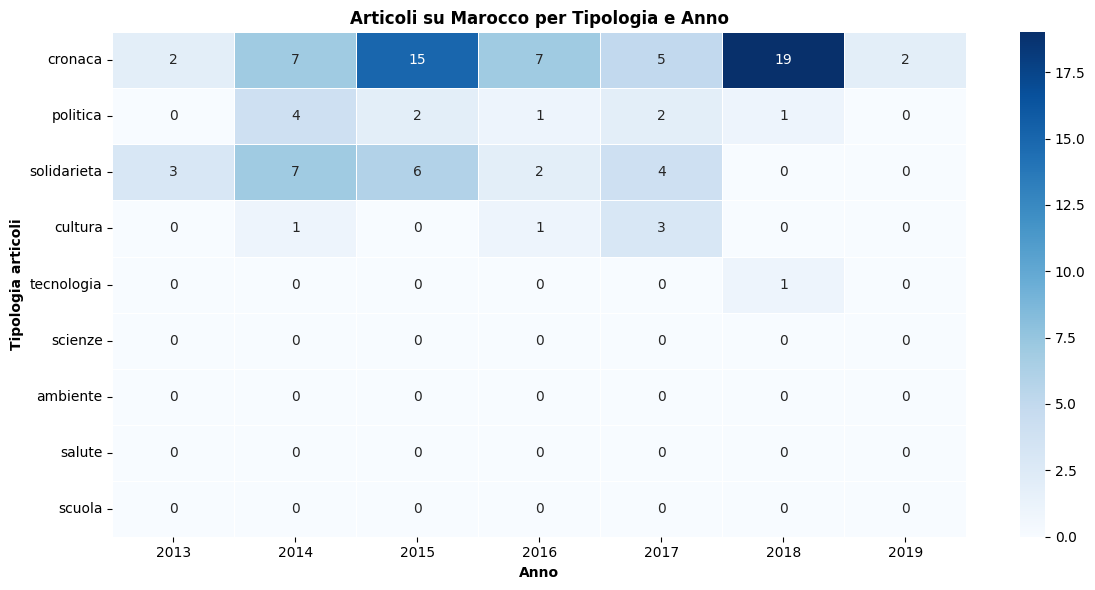

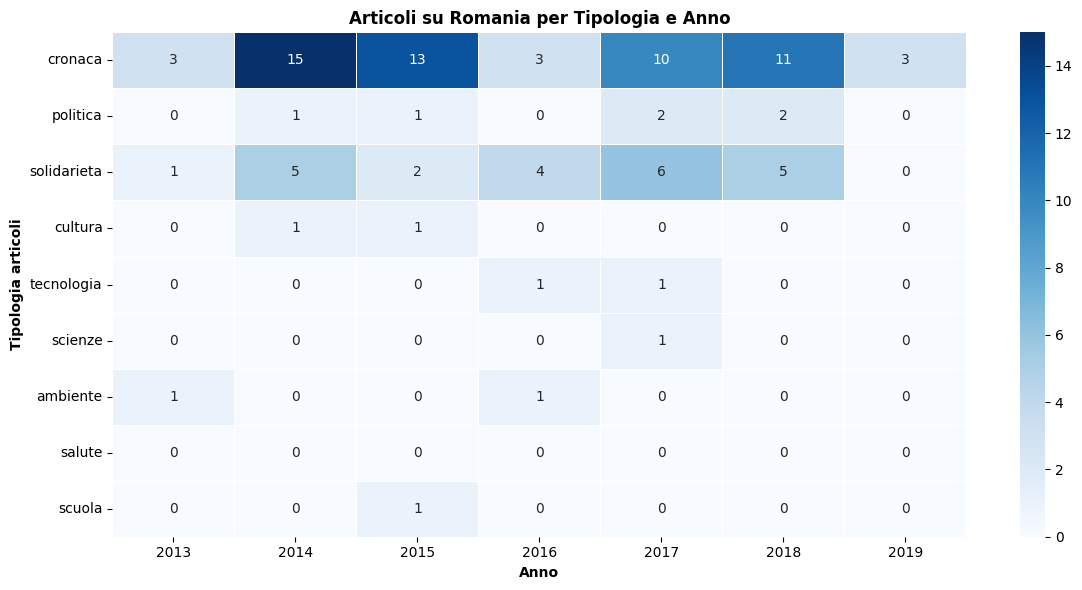

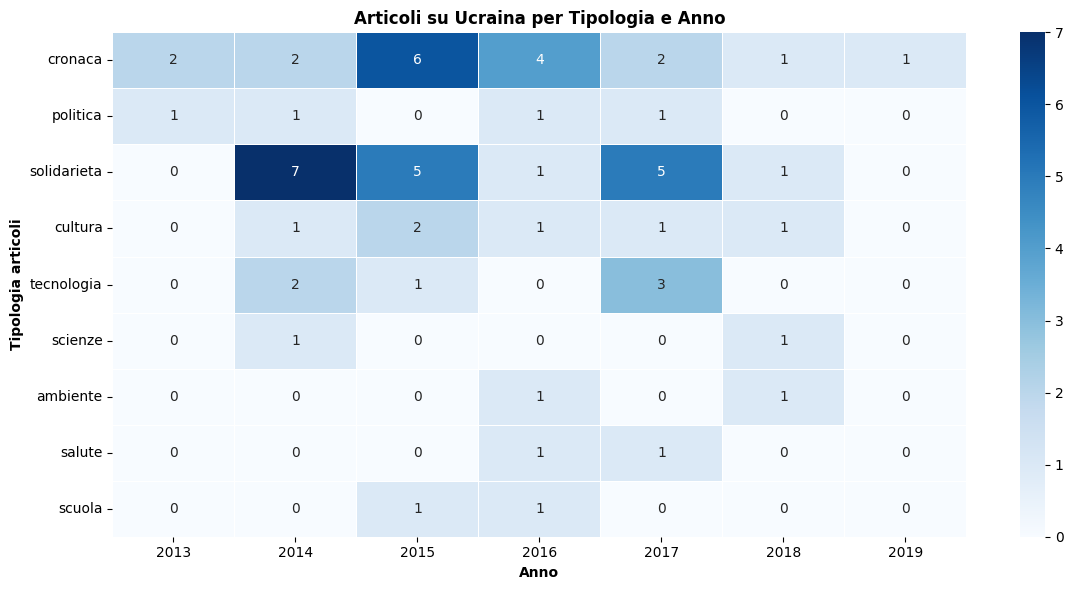

In [62]:
def heatmap_per_stato(df, tipologie):

    df_quantita = (df.groupby(["Stato di cittadinanza", "anno", "tipologia"])
                   .size()
                   .reset_index(name="quantita"))

    df_quantita["anno"] = df_quantita["anno"].astype(int)

    for stato, df_stato_quantita in df_quantita.groupby("Stato di cittadinanza"):
        tabella = df_stato_quantita.pivot_table(index = "tipologia", columns = "anno", values = "quantita", fill_value = 0)
        tabella = tabella.reindex(index=tipologie, fill_value=0)

        plt.figure(figsize=(12, 6))
        sns.heatmap(tabella, annot=True, fmt=".0f", cmap="Blues", linewidths=0.5)
        plt.title(f"Articoli su {stato} per Tipologia e Anno", fontweight="bold")
        plt.xlabel("Anno", fontweight="bold")
        plt.ylabel("Tipologia articoli", fontweight="bold")
        plt.tight_layout()
        plt.show()
        
heatmap_per_stato(df_euristica_persona, tipologie_rilevanti)

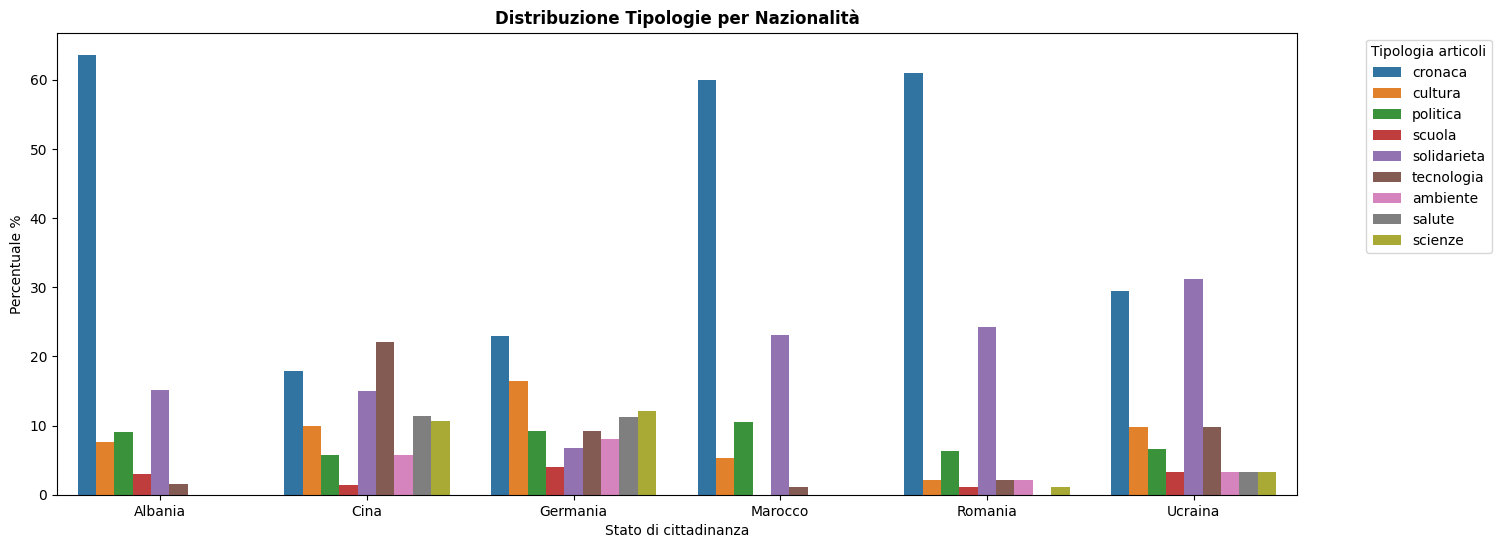

In [63]:
df_grafico_confronto = df_euristica_persona.copy()
df_grafico_confronto_perc = df_grafico_confronto.groupby(["Stato di cittadinanza", "tipologia"]).size().reset_index(name="quantita")
df_grafico_confronto_perc["totale_stato"] = df_grafico_confronto_perc.groupby("Stato di cittadinanza")["quantita"].transform("sum")
df_grafico_confronto_perc["percentuale"] = (df_grafico_confronto_perc["quantita"] / df_grafico_confronto_perc["totale_stato"]) * 100

plt.figure(figsize=(16, 6))
sns.barplot(data=df_grafico_confronto_perc, x="Stato di cittadinanza", y="percentuale", hue="tipologia")
plt.title("Distribuzione Tipologie per Nazionalità", fontweight="bold")
plt.xlabel("Stato di cittadinanza")
plt.ylabel("Percentuale %")
plt.legend(title="Tipologia articoli", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

*I dati mostrano che il giornalismo italiano nel periodo 2013–2019 non rappresenta le diverse nazionalità in modo uniforme, ma costruisce profili narrativi molto differenziati a seconda della cittadinanza delle persone di cui scrive.*

*Per le nazionalità **Albania, Marocco, Romania**, la persona straniera entra nel racconto giornalistico prevalentemente quando è coinvolta in un fatto di cronaca. Questo non è un dato neutro: significa che per il lettore medio queste comunità esistono mediaticamente prevalentemente in quanto protagoniste di episodi problematici, mentre sono pressoché assenti dai contesti culturali, politici o scientifici.*

*Le altre nazionalità in esame godono di un trattamento diverso. La persona tedesca viene raccontata in contesti di cultura, economia, politica. La persona ucraina viene rappresentata prevalentemente come soggetto di solidarietà, una visibilità che, pur non stigmatizzante, tende a costruire un'immagine di fragilità piuttosto che di presenza attiva. La persona cinese emerge spesso in contesti tecnologici ed economici, con un profilo più attivo.*

*Nel complesso, i dati suggeriscono la presenza di una gerarchia narrativa implicita nel giornalismo analizzato: alcune nazionalità vengono associate a problemi, altre a eventi, altre ancora a contributi. Le scelte su chi raccontare, in quale contesto e con quale tono concorrono a formare l'immagine pubblica di intere comunità, indipendentemente da quante persone le compongano o da come esse effettivamente vivano nel paese.*

### **Il tono del racconto: un indice di confronto**

*Per analizzare concretamente in che modo vengono raccontate le diverse nazionalità, abbiamo creato un punteggio complessivo (un indice) basato semplicemente sulle sezioni del giornale in cui compaiono gli articoli.*

*Il punto di partenza è molto intuitivo: la sezione in cui il quotidiano decide di collocare una notizia stabilisce l'orientamento e l'atmosfera del racconto. Per poter calcolare e visualizzare questo dato, abbiamo assegnato a ogni tipo di articolo un valore diviso su tre livelli:*

* ***I contesti positivi (da +1.0 a +0.3):*** *scienze, cultura, tecnologia, scuola e solidarietà. Rappresentano un racconto legato alle competenze, al valore delle persone o all'accoglienza e all'aiuto.*
* ***I contesti negativi (da -0.3 a -1.0):*** *cronaca, salute e ambiente. Rappresentano un racconto legato a problemi, emergenze o difficoltà, con la **cronaca** impostata come valore negativo massimo (-1.0).*
* ***Il contesto neutro (0):*** *la politica. Rappresenta il dibattito sulle leggi e sulle istituzioni, senza un taglio positivo o negativo diretto sulle persone.*

*L'indice finale è la media dei pesi assegnati a ciascun articolo classificato come "persona". Di conseguenza:*
* *I valori **positivi** indicano un racconto orientato all'integrazione e al prestigio.*
* *I valori **negativi** indicano un racconto schiacciato sulla cronaca e sui problemi.*
* *I valori **vicini allo zero** indicano una forte presenza di articoli di politica o un sostanziale equilibrio.*

*I punteggi scelti non vanno letti come un voto assoluto alla qualità del giornale, ma come uno strumento di confronto. Cambiare leggermente i pesi cambierebbe i numeri esatti, ma non la direzione generale delle linee. Questo indice ci serve quindi per vedere a colpo d'occhio e confrontare come cambia il tono del racconto per le varie nazioni nel corso del periodo considerato.*

*Per garantire una maggiore robustezza dell'analisi, l'anno 2019 è stato escluso dal calcolo dell'indice. Il numero particolarmente ridotto di articoli disponibili per quel periodo avrebbe infatti reso i risultati eccessivamente sensibili a singoli casi anomali **(outliers)**, con il rischio di alterare il valore medio e compromettere la confrontabilità con gli altri anni.*

In [64]:
pesi_tipologie = {"scienze": 1.0,      
                  "cultura": 0.8,
                  "tecnologia": 0.6,   
                  "scuola": 0.4,       
                  "solidarieta": 0.3,  
                  "politica": 0.0,     
                  "ambiente": -0.3,    
                  "salute": -0.4, 
                  "cronaca": -1.0}

In [65]:
df_racconto = df_euristica_persona.copy()
df_racconto = df_racconto[df_racconto["anno"].astype(int) != 2019]
df_pesi = pd.DataFrame({"tipologia": list(pesi_tipologie.keys()), "peso": list(pesi_tipologie.values())})
df_racconto = df_racconto.merge(df_pesi, on="tipologia")
df_indice_tono = df_racconto.groupby(["anno", "Stato di cittadinanza"])["peso"].mean().reset_index()
df_indice_tono.columns = ["anno", "nazionalita", "indice_tono"]
df_indice_tono["anno"] = df_indice_tono["anno"].astype(int)
df_indice_tono["indice_tono"] = df_indice_tono["indice_tono"].round(3)
df_indice_tono

,anno,nazionalita,indice_tono
0,2013,Albania,-0.567
1,2013,Cina,-0.242
2,2013,Germania,0.086
3,2013,Marocco,-0.220
4,2013,Romania,-0.600
5,2013,Ucraina,-0.667
6,2014,Albania,-0.371
7,2014,Cina,0.400
8,2014,Germania,0.282
9,2014,Marocco,-0.216


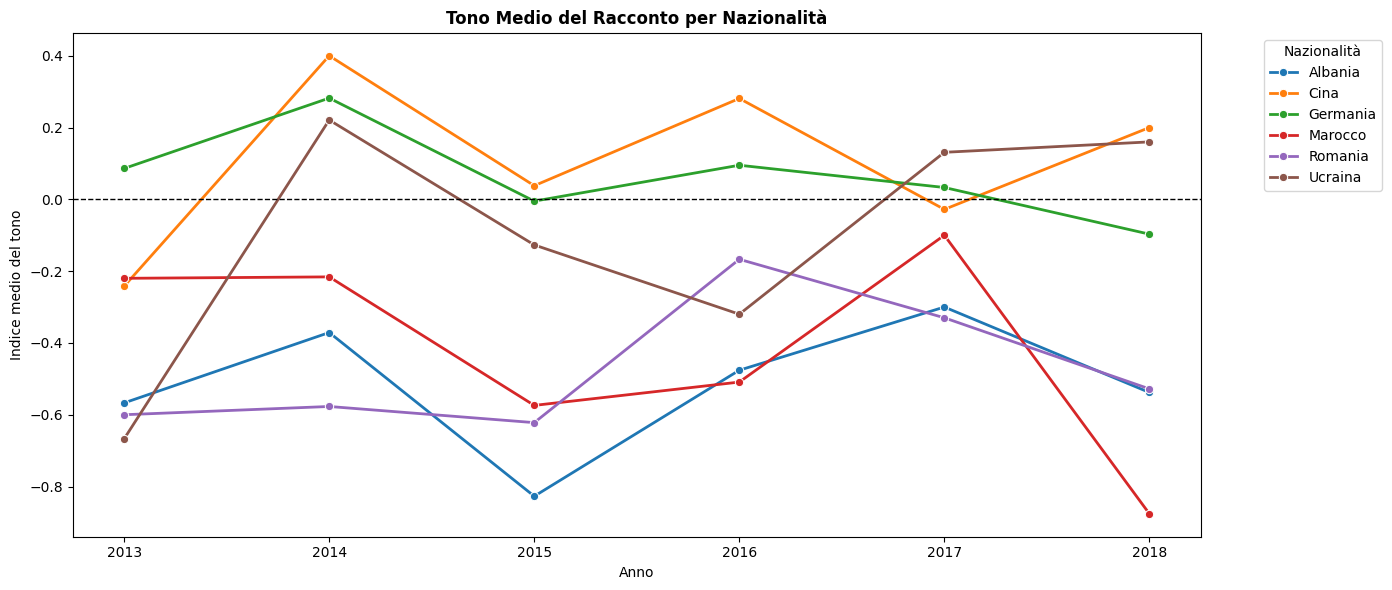

In [66]:
plt.figure(figsize=(14, 6))
sns.lineplot(data=df_indice_tono, x="anno", y="indice_tono", hue="nazionalita", marker="o", linewidth=2)
plt.axhline(0, color="black", linewidth=1, linestyle="--")
plt.xticks(df_indice_tono["anno"].unique())
plt.title("Tono Medio del Racconto per Nazionalità", fontweight="bold")
plt.xlabel("Anno")
plt.ylabel("Indice medio del tono")
plt.legend(title="Nazionalità", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

### **Interpretazione del grafico**

*La linea dello zero rappresenta la soglia che separa i contesti mediamente positivi da quelli mediamente negativi. I valori superiori a zero indicano una prevalenza di contesti associati a scienza, cultura, tecnologia, scuola o solidarietà, mentre i valori inferiori a zero indicano una prevalenza di contesti legati a cronaca, salute o ambiente. Nel complesso, il grafico mostra che molte nazionalità si collocano spesso sotto lo zero, ma con andamenti molto diversi tra loro.*

**Germania e Cina: gli andamenti più equilibrati o positivi** <br> *Germania e Cina sono le nazionalità che presentano più spesso valori vicini o superiori allo zero. La Cina passa da un valore negativo nel 2013 (-0.24) a valori positivi nel 2014 (+0.40), 2015 (+0.04), 2016 (+0.28) e 2018 (+0.20), con una lieve flessione nel 2017 (-0.03). Anche la Germania mantiene valori generalmente positivi o prossimi allo zero fino al 2017, con il valore più alto nel 2014 (+0.28), con un lieve peggioramento nel 2018 (-0.10). Queste due nazionalità risultano quindi meno stabilmente associate a contesti negativi rispetto alle altre, pur mostrando alcune oscillazioni nel tempo.*

**Albania, Marocco, Romania: il racconto prevalentemente negativo** <br> *Albania, Marocco e Romania presentano quasi sempre valori inferiori a zero. L'Albania mostra sempre valori negativi, con il punto più basso nel 2015 (-0.83). Il Marocco mantiene valori negativi in tutti gli anni, con un livello particolarmente basso nel 2018 (-0.88). Anche la Romania rimane sempre sotto lo zero, con valori molto negativi nel 2013 (-0.60), 2014 (-0.58), 2015 (-0.62), 2018 (-0.53). Questi dati suggeriscono che queste comunità tendano a essere rappresentate prevalentemente attraverso contesti legati alla cronaca o a situazioni problematiche.*

**Ucraina: l'andamento più instabile** <br> *L'Ucraina presenta l'andamento più irregolare. Parte da un valore negativo nel 2013 (-0.67), passa a un valore positivo nel 2014 (+0.22), torna sotto lo zero nel 2015 (-0.13) e nel 2016 (-0.32), risale nel 2017 (+0.13) e nel 2018 (+0.16). Questa alternanza suggerisce che il racconto delle persone ucraine sia particolarmente sensibile agli eventi del periodo: in alcuni anni prevalgono contesti di solidarietà o attenzione umanitaria, mentre in altri emergono contesti più negativi o legati alla cronaca.*

*Nel complesso, il grafico mostra che il quotidiano non tratta le nazionalità in modo uniforme. Alcune comunità, come Cina e Germania, presentano un tono medio più equilibrato o positivo, spesso legato a cultura, scienza, tecnologia o altri contesti meno problematici. Altre, come Albania, Marocco e Romania, risultano invece associate in modo più stabile a un racconto negativo o di cronaca. L'Ucraina occupa una posizione intermedia e molto variabile, influenzata dagli eventi storici e politici del periodo analizzato. Questi profili narrativi differenziati sono coerenti con l'esistenza di una gerarchia narrativa implicita: i media non si limitano a non rispecchiare i numeri demografici, ma costruiscono anche rappresentazioni qualitativamente asimmetriche delle diverse comunità.*

# ___________________________________________________________________________________________________________________________________________________

## **3. Conclusioni**

*Questo progetto è nato da una domanda di ricerca fondamentale: la rappresentazione delle diverse nazionalità nei media italiani riflette la loro effettiva presenza demografica sul territorio nazionale?*

*Attraverso l'integrazione dei dati ISTAT sulla popolazione residente per cittadinanza, dell'archivio degli articoli de "la Repubblica" e delle procedure di pulizia testuale adottate, è stato possibile analizzare il rapporto tra consistenza demografica e visibilità mediatica. I risultati ottenuti suggeriscono che la copertura giornalistica non sia determinata principalmente dalla numerosità delle comunità presenti in Italia, ma risponda a dinamiche informative, eventi di attualità e specifiche logiche editoriali indipendenti.*

---

### **I risultati principali del progetto**

*L'analisi ha evidenziato due risultati centrali:*

1. **La visibilità mediatica non dipende dalla consistenza numerica delle comunità:** *Le correlazioni statistiche mostrano che l'andamento della popolazione residente non rappresenta un fattore sufficiente a spiegare l'attenzione dedicata dal quotidiano alle diverse nazionalità. Il caso della Romania conferma una tendenza significativa: una comunità che cresce e si stabilizza sul territorio italiano tende a ottenere meno attenzione mediatica nel tempo. Anche il caso del Marocco, che presenta una correlazione positiva moderatamente elevata, non contraddice tale conclusione. In questo caso, infatti, la relazione osservata sembra essere associata alla costante presenza di contenuti riconducibili alla cronaca, piuttosto che a un effettivo interesse proporzionale alla crescita demografica.*

2. **Le nazionalità tendono a essere associate a specifici contesti narrativi:** *La seconda parte dell'analisi ha evidenziato come determinate nazionalità vengano rappresentate all'interno di schemi narrativi ricorrenti. L'esame delle sezioni giornalistiche e degli indicatori relativi al tono del racconto mostra una chiara differenziazione tra gruppi nazionali. Albania, Romania e Marocco risultano prevalentemente associati alla cronaca, che rappresenta circa il 60% degli articoli a loro dedicati. Al contrario, Cina e Germania sono più frequentemente inserite in contesti legati all'economia, alla tecnologia, alla scienza e alla cultura. L'Ucraina occupa una posizione peculiare, caratterizzata da una forte associazione con temi di emergenza umanitaria e solidarietà internazionale.*

---

### **Considerazioni finali**

*Nel complesso, i risultati suggeriscono che la rappresentazione mediatica delle nazionalità in Italia sia guidata principalmente da criteri di notiziabilità, rilevanza editoriale e interesse pubblico, piuttosto che dalla distribuzione demografica delle comunità presenti nel Paese. I media tendono quindi a costruire immagini pubbliche delle diverse nazionalità attraverso cornici narrative relativamente stabili, che possono contribuire a rafforzare specifiche associazioni tematiche e rappresentazioni collettive. In questo senso, la visibilità mediatica appare come il risultato di processi selettivi che rispondono maggiormente alle logiche dell'informazione e dell'attualità che alla semplice consistenza numerica delle comunità rappresentate.*
